This notebook runs under the environment neuro on Julie's IMac and MacBookPro

In [1]:
import os
import sys
import pynwb
import h5py
import numpy as np
import pandas as pd
import scipy.stats
from scipy.signal import filtfilt, iirnotch
import matplotlib.pyplot as plt
from pynwb.epoch import TimeIntervals
from datetime import datetime, timedelta
from soundsig.sound import spec_colormap, BioSound
import time
from IPython.display import display, clear_output
from sklearn.decomposition import PCA
import pickle

# local code
sys.path.append(os.path.join("/Users/elie/Documents/CODE/strfPy/module"))
from strfpy.timeFreq import timefreq_raw


## Load the nwb file

In [2]:
#site = '/Users/elie/Documents/neuro_PurWhi_WF/PurWhi127037F__250329_122705_site1_op_re_ks4__phy_JEE_20251108.nwb'
site ='/Users/elie/Library/CloudStorage/Box-Box/ManipBerkeleyZF/neuro_PurWhi_WF/PurWhi127037F__250329_122705_site1_op_re_ks4__phy_JEE_20251108.nwb'
nwb = pynwb.NWBHDF5IO(site, mode='r').read()

In [3]:
nwb

root pynwb.file.NWBFile at 0x5479152480
Fields:
  acquisition: {
    LFP <class 'pynwb.ecephys.ElectricalSeries'>,
    audcode_events <class 'hdmf.common.table.DynamicTable'>,
    audio <class 'pynwb.base.TimeSeries'>,
    ttl_events <class 'hdmf.common.table.DynamicTable'>,
    unit_waveforms <class 'hdmf.common.table.DynamicTable'>
  }
  devices: {
    cambridge_H10.prb <class 'pynwb.device.Device'>
  }
  electrode_groups: {
    cambridge_H10.prb <class 'pynwb.ecephys.ElectrodeGroup'>
  }
  electrodes: electrodes <class 'pynwb.ecephys.ElectrodesTable'>
  experimenter: ['Thomas, Logan']
  file_create_date: [datetime.datetime(2025, 11, 12, 21, 53, 25, 209277, tzinfo=tzoffset(None, -28800))]
  identifier: c8ef0ee0-0b3f-4be5-bbc9-bbd3347098bc
  institution: University of California, Berkeley
  intervals: {
    operant_trials <class 'pynwb.epoch.TimeIntervals'>,
    playback_trials <class 'pynwb.epoch.TimeIntervals'>,
    pyoperant_experiments <class 'pynwb.epoch.TimeIntervals'>,
    unit_intervals <class 'pynwb.epoch.TimeIntervals'>
  }
  lab: Theunissen Lab
  processing: {
    behavior <class 'pynwb.base.ProcessingModule'>
  }
  session_description: OperantEphys/PurWhi127037F
  session_start_time: 2025-03-29 12:27:05-07:00
  stimulus: {
    Ag_Stim_10_BlaLbl8026_110425-AggC-02.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_10_GraLbl0457_110606-AggC-12.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_10_LblBla4419_130417-Ag-03.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_10_PurRas20dd_110425-AggC-08.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_10_WhiBlu5698_110404-AggC-10.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_10_WhiLbl0010_110606-AggC-13.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_1_WhiBlu4818_110404-AggC-05.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_1_YelOra2575_110622-AggC-04.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_BlaLbl8026_110427-AggC-03.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_GraLbl0457_110606-AggC-06.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_LblBla4419_130416-Ag-02.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_LblRed0613_111006-AggC-25.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_WhiBlu4818_110404-AggC-06.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_WhiBlu5698_110304-AggC-04.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_WhiRas44dd_110616-AggC-08.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_3_BluRas07dd_110601-AggC-20.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_3_PurRas20dd_110425-AggC-09.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_3_WhiBlu5698_110304-AggC-06.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_4_BluRas61dd_110502-AggC-12.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_4_LblBla4419_130417-Ag-03.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_5_GraLbl0457_110606-AggC-09.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_5_LblRed0613_111006-AggC-28.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_5_PurRas20dd_110606-AggC-17.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_5_WhiBlu4818_110404-AggC-07.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_5_WhiLbl0010_110608-AggC-26.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_6_BluRas61dd_110502-AggC-10.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_6_LblRed0613_110921-AggC-08.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_GraLbl0457_110606-AggC-12.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_LblBla4419_130416-Ag-01.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_LblRed0613_111004-AggC-14.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_PurRas20dd_110606-AggC-19.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_WhiBlu5698_110405-AggC-11.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_YelOra2575_110729-AggC-23.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_8_PurRas20dd_110606-AggC-20.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_8_WhiLbl0010_110606-AggC-09.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_8_YelOra2575_110728-AggC-19.wav <class 

In [4]:
audcode_events = nwb.acquisition['audcode_events'].to_dataframe()
print('there are %d operant trials in this nwb file' % len(audcode_events))
audcode_events[0:20]

there are 562 operant trials in this nwb file


,timestamp,code,object,action,repetition,trial,md5
id,,,,,,,
0,418.385467,Speaqueu00000001db014097b4ebd4674ee7db4605e8cb12,Spea,queu,0,1,db014097b4ebd4674ee7db4605e8cb12
1,495.395067,Speaqueu000000027ac1525447a74b01936399aee8bffb62,Spea,queu,0,2,7ac1525447a74b01936399aee8bffb62
2,545.488833,Speaqueu00000003f30292bb03eafc7a39556837d1467e1c,Spea,queu,0,3,f30292bb03eafc7a39556837d1467e1c
3,603.538800,Speaqueu00000004be5c467a863ea32de35563b9a2d8eef7,Spea,queu,0,4,be5c467a863ea32de35563b9a2d8eef7
4,669.094733,Speaqueu000000055fe990ab027f9eba35f8252f5442b8b6,Spea,queu,0,5,5fe990ab027f9eba35f8252f5442b8b6
5,671.028067,Speaqueu00000006ed2ac4c735a7f3f5deb46d2e8bc3260c,Spea,queu,0,6,ed2ac4c735a7f3f5deb46d2e8bc3260c
6,712.387667,Speaqueu0000000729ce62ccdf10a84c8ab03a8a5c8c7f56,Spea,queu,0,7,29ce62ccdf10a84c8ab03a8a5c8c7f56
7,772.547300,Speaqueu00000008b8540105f7bd1e2ec541964e9667a773,Spea,queu,0,8,b8540105f7bd1e2ec541964e9667a773
8,860.858133,Speaqueu000000090cad41e1ff750647a81ff803efa8accc,Spea,queu,0,9,0cad41e1ff750647a81ff803efa8accc


In [5]:
audcode_events[115:125]

,timestamp,code,object,action,repetition,trial,md5
id,,,,,,,
115,10803.989233,Speaqueu00000105b77381d288353ea8b14bfb22c0ef94a4,Spea,queu,0,105,b77381d288353ea8b14bfb22c0ef94a4
116,10818.635467,Speaqueu0000010606a86b34e042ef18028f2a830143b2c8,Spea,queu,0,106,06a86b34e042ef18028f2a830143b2c8
117,10843.964567,Speaqueu000001071452acf101c71afb9d9ae833091ba655,Spea,queu,0,107,1452acf101c71afb9d9ae833091ba655
118,10857.615700,Speaqueu00000108ea53d415adad83cf4ba4d8cdbc8a0d66,Spea,queu,0,108,ea53d415adad83cf4ba4d8cdbc8a0d66
119,10915.492233,Speaqueu00000109201a831f1b7e814ae350a0f1b596f308,Spea,queu,0,109,201a831f1b7e814ae350a0f1b596f308
120,10916.763467,Speaqueu000001102afa462c19c22ea3c74ecd782f216a19,Spea,queu,0,110,2afa462c19c22ea3c74ecd782f216a19
121,10953.511867,Speaqueu00000111df4ba877abe6d99a0dc2d55e17aeb8a4,Spea,queu,0,111,df4ba877abe6d99a0dc2d55e17aeb8a4
122,13416.981833,Speaqueu00010124aad1450a92937dfc03c1de6249bf1f71,Spea,queu,1,124,aad1450a92937dfc03c1de6249bf1f71
123,13452.253233,Speaqueu0000012559f1274510fc7426aecbc86b821d0816,Spea,queu,0,125,59f1274510fc7426aecbc86b821d0816


# Function definitions

## Retrieve audio data per trial, plot spectrograms per trial

In [6]:
# lets take one trial and compare the spectrogram of the audio directly routed to the intan to the spectrogram of the microphone data as recorded by INTAN
def get_audio_data(nwb, trial, buffer = [0,0]):
    fs = nwb.acquisition['audio'].rate
    audio_data = nwb.acquisition['audio'].data
    start_id = int(trial.start_time.item() * fs - buffer[0] * fs)
    end_id = int(trial.stop_time.item() * fs + buffer[1] * fs)
    audio_trial = audio_data[start_id:end_id]
    return audio_trial[:,1], audio_trial[:,0], fs

def plot_trial_spectros(trial, notchFilterFlag=0):
    # Spectrogram paramteters.
    stim_params = {}
    stim_params['fband'] = 50
    stim_params['nstd'] = 6
    stim_params['high_freq'] = 8000
    stim_params['low_freq'] = 250
    stim_params['log'] = 1
    stim_params['stim_rate'] = 1000  # Sample rate of spectrogram
    DBNOISE = 50
    # Colormap for plotting spectrograms
    spec_colormap()   # defined in sound.py

    # get the audio data for that trial
    mic_signal_trial, speaker_signal_trial,rate = get_audio_data(nwb, trial)

    # filter the 1200Hz contamination sound if requested
    if notchFilterFlag:
        fs = rate
        f0 = 1200.0  # Frequency to be removed from signal (Hz)
        Q = 20.0  # Quality factor
        b, a = iirnotch(f0, Q, fs)
        mic_signal_trial = filtfilt(b, a,mic_signal_trial)
        speaker_signal_trial = filtfilt(b, a,speaker_signal_trial)
        
    # First figure for the speaker signal as directly acquired by Intan
    f, (ax1, ax2) = plt.subplots(2, 1, sharex=True, dpi=100, figsize = (8,4))

    tfrep = timefreq_raw(speaker_signal_trial, rate, 'ft', params=stim_params)
    cmap = plt.get_cmap('SpectroColorMap')

    minSpect = tfrep['spec'].max()-DBNOISE
    maxB = tfrep['spec'].max()
    ax1.imshow(tfrep['spec'], extent=[tfrep['t'][0], tfrep['t'][-1], tfrep['f'][0]*1e-3, tfrep['f'][-1]*1e-3],
                aspect='auto', interpolation='nearest', origin='lower', cmap=cmap, vmin=minSpect, vmax=maxB)
    ax1.set_ylim(0, 8)
    ax1.set_ylabel('Frequency (kHz)')
    ax1.set_title('speaker signal')

    tval = np.arange(stop=len(speaker_signal_trial))/rate
    ax2.plot(tval, speaker_signal_trial)
    ax2.set_xlabel('Time (s)')
    
    

    # Second for the microphone
    f, (ax1, ax2) = plt.subplots(2, 1, sharex=True, dpi=100, figsize = (8,4))

    tfrep = timefreq_raw(mic_signal_trial, rate, 'ft', params=stim_params)
    minSpect = tfrep['spec'].max()-DBNOISE
    maxB = tfrep['spec'].max()
    ax1.imshow(tfrep['spec'], extent=[tfrep['t'][0], tfrep['t'][-1], tfrep['f'][0]*1e-3, tfrep['f'][-1]*1e-3],
                aspect='auto', interpolation='nearest', origin='lower', cmap=cmap, vmin=minSpect, vmax=maxB)
    ax1.set_ylim(0, 8)
    ax1.set_ylabel('Frequency (kHz)')
    ax1.set_title('microphone signal')

    tval = np.arange(stop=len(mic_signal_trial))/rate
    ax2.plot(tval, mic_signal_trial)
    ax2.set_xlabel('Time (s)')
    plt.show()
    return

## retrieve all neuron responses or specific neuron responses for a given trial
Time varying rate is calculated with a gaussian kde

In [7]:
def get_allneural_data_pertrial(nwb, trial,buffer=[0,0],kde_width = 30, PlotFlag=0,MicFlag=0, NotchFilterFlag=0, NeuronID = []):
    # kde_width is in ms
    start = int(-buffer[0]*1000)
    stop = int(trial.stop_time*1000 - trial.start_time*1000 + buffer[1]*1000)
    if PlotFlag:
        fig1, (ax1, ax2) = plt.subplots(2, 1, sharex=True, dpi=100, figsize = (8,4))
        ax1.set_xlim(start, stop)
        #ax1.set_xlabel('Time (ms)')

         # Spectrogram paramteters.
        stim_params = {}
        stim_params['fband'] = 50
        stim_params['nstd'] = 6
        stim_params['high_freq'] = 8000
        stim_params['low_freq'] = 250
        stim_params['log'] = 1
        stim_params['stim_rate'] = 1000  # Sample rate of spectrogram
        DBNOISE = 50
        # Colormap for plotting spectrograms
        spec_colormap()   # defined in sound.py

        # get the audio data for that trial
        mic_signal_trial, speaker_signal_trial,rate = get_audio_data(nwb, trial, buffer)

        # Plot either the spectro of the microphone or the spectro of the speaker signal as directly acquired by Intan
        if MicFlag: # microphone signal requested
            if NotchFilterFlag:
                fs = rate
                f0 = 1200.0  # Frequency to be removed from signal (Hz)
                Q = 20.0  # Quality factor
                b, a = iirnotch(f0, Q, fs)
                mic_signal_trial = filtfilt(b, a,mic_signal_trial)
            tfrep = timefreq_raw(mic_signal_trial, rate, 'ft', params=stim_params)
            ax1.set_title('microphone signal')
        else:
            if NotchFilterFlag:
                fs = rate
                f0 = 1200.0  # Frequency to be removed from signal (Hz)
                Q = 20.0  # Quality factor
                b, a = iirnotch(f0, Q, fs)
                speaker_signal_trial = filtfilt(b, a,speaker_signal_trial)
            tfrep = timefreq_raw(speaker_signal_trial, rate, 'ft', params=stim_params)
            ax1.set_title('speaker signal')
        cmap = plt.get_cmap('SpectroColorMap')
        minSpect = tfrep['spec'].max()-DBNOISE
        maxB = tfrep['spec'].max()
        ax1.imshow(tfrep['spec'], extent=[tfrep['t'][0]*1000 - buffer[0]*1000, tfrep['t'][-1]*1000 - buffer[0]*1000, tfrep['f'][0]*1e-3, tfrep['f'][-1]*1e-3],
                aspect='auto', interpolation='nearest', origin='lower', cmap=cmap, vmin=minSpect, vmax=maxB)
        ax1.set_ylim(0, 8)
        ax1.set_ylabel('Frequency (kHz)')
        

        # second plot for the neural data of the current neuron
        ax2.set_xlabel('Time (ms)')
        ax2.set_ylabel('spike rate (Hz)')
        line1, = ax2.plot([], [], 'r-')
        ax3 = ax2.twinx()
        line2, = ax3.plot([], [], 'k', marker='o', markersize=2, linestyle='None')
        ax3.set_ylim(-0.1,4)
        ax3.set_yticks([])
        
    units = nwb.units.to_dataframe()
    Nunits = len(units)
    neuralpop_data=[]
    if not NeuronID:
        cellrange = range(Nunits)
    else:
        cellrange = range(NeuronID,NeuronID+1)
    for uu in cellrange:
        spike_indices = np.argwhere((units.iloc[uu].spike_times >= (trial.start_time-buffer[0])) & (units.iloc[uu].spike_times <= (trial.stop_time+ buffer[1])))
        spike_times = units.iloc[uu].spike_times[spike_indices].flatten()*1000 - trial.start_time*1000 # in ms alligned to sound onset
        xt = np.linspace(start= start, stop=stop, num = stop-start+1, endpoint=True)
        if len(spike_times)>1:
            if PlotFlag:
                print('number of spikes for neuron ' + str(uu) + ': ' + str(len(spike_times)))
            kde = scipy.stats.gaussian_kde(spike_times, bw_method= kde_width/np.std(spike_times))
            spikeRate = kde.evaluate(xt)*len(spike_times)*1000.0 # in spike/s
            neuralpop_data.append(spikeRate)
        
        else:
            if PlotFlag:
                print('Not enough spikes for neuron ' + str(uu) + ': ' + str(len(spike_times)))
            spikeRate = np.zeros(xt.shape)
            neuralpop_data.append(spikeRate)
        
        if PlotFlag:
            # Update the line data for spike rate
            line1.set_data(xt, spikeRate)
            ax2.set_ylim(0,max(spikeRate)+1)
            ax2.set_title('Neuron ' + str(uu))

        
            # update the scatter plot data for spike arrival times
            line2.set_data(spike_times, [0.5]*len(spike_times) - np.random.rand(len(spike_times))/2) # plot spike times alligned to sound onset
        
            # update the title
            ax2.set_title('Neuron ' + str(uu))

            # save the figure if requested
            #plt.savefig('/Users/elie/Library/CloudStorage/Box-Box/ERC/WorkingFolder2026/Figures/Trial131_Neuron82.eps')

            fig2, axs = plt.subplots(nrows=2, ncols=2, sharex=True, dpi=100, figsize = (4,4))
            waveforms = nwb.acquisition['unit_waveforms'].to_dataframe()
            fs = nwb.acquisition['audio'].rate
            MaxY = 0
            MinY = 0
            for cc, ax in enumerate(axs.flatten()):
                wavemean=waveforms[waveforms.unit_id == uu].waveform_mean[uu][cc,]
                wavesd = waveforms[waveforms.unit_id == uu].waveform_sd[uu][cc,]
                xtime = np.array(range(0,len(wavemean)))/fs*1000
                ax.fill_between(xtime, wavemean-wavesd, wavemean+wavesd, color = 'k', alpha = 0.3)
                ax.plot(xtime, wavemean, 'k-')
                MaxY = max(max(ax.get_ylim()), MaxY)
                MinY = min(min(ax.get_ylim()), MinY)
            for cc, ax in enumerate(axs.flatten()):
                ax.set_ylim(MinY, MaxY)
                if cc==1 or cc==3:
                    ax.set_yticks([])
                if cc==0 or cc==2:
                    ax.set_ylabel('Voltage(uV)')
                if cc==2 or cc==3:
                    ax.set_xlabel('Time (ms)')
            
            # save the figure if requested
            #plt.savefig('/Users/elie/Library/CloudStorage/Box-Box/ERC/WorkingFolder2026/Figures/Trial131_Neuron82_spike_shape.eps')

            # Clear the output of the current cell and display the new figure
            clear_output(wait=True)
            display(fig1)
            display(fig2)
            time.sleep(1)
            plt.close(fig1)
            plt.close(fig2)

            # Redraw the figure
            #plt.draw()
            #plt.show() 
    
            # Pause for a short period to allow the GUI event loop to process changes
        #plt.pause(0.5)
    #if PlotFlag:
        #plt.ioff() # Turn off interactive mode
        #plt.show()
    return neuralpop_data


## Plot all neural responses and spectrogram for a given trial
Time varying rate is calculated with a Gaussian kde

In [8]:
def plot_trial_neuropop(nwb, trial, buffer, kde_width, MicFlag=0, NotchFilterFlag=1,MinRate = 0):
    # Spectrogram paramteters.
    stim_params = {}
    stim_params['fband'] = 50
    stim_params['nstd'] = 6
    stim_params['high_freq'] = 8000
    stim_params['low_freq'] = 250
    stim_params['log'] = 1
    stim_params['stim_rate'] = 1000  # Sample rate of spectrogram
    DBNOISE = 60
    # Colormap for plotting spectrograms
    spec_colormap()   # defined in sound.py

    # get the audio data for that trial
    mic_signal_trial, speaker_signal_trial,fs = get_audio_data(nwb, trial, buffer)

    # get the neural data for that trial
    neuropop_trial = np.array(get_allneural_data_pertrial(nwb,trial,buffer,kde_width))

    # apply min Rate threshold if requested
    if MinRate>0:
        mean_rate = np.nanmean(neuropop_trial, axis = 1, keepdims=True)
        ind_high_rate = np.argwhere(mean_rate.flatten()>MinRate).flatten()
        neuraldata_4plot = np.array(neuropop_trial)[ind_high_rate]
        print('Number of units: ' + str(len(ind_high_rate)))
    else:
        neuraldata_4plot = neuropop_trial
        print('Number of units: ' + str(neuraldata_4plot.shape[0]))


    # First plot for the spectro of the speaker signal as directly acquired by Intan
    f, (ax1, ax2) = plt.subplots(2, 1, sharex=True, dpi=100, figsize = (8,12), height_ratios = (1,4))
    if MicFlag:
        if NotchFilterFlag:
            f0 = 1200.0  # Frequency to be removed from signal (Hz)
            Q = 10.0  # Quality factor
            b, a = iirnotch(f0, Q, fs)
            mic_signal_trial = filtfilt(b, a,mic_signal_trial)
        tfrep = timefreq_raw(mic_signal_trial, fs, 'ft', params=stim_params)
        ax1.set_title('microphone signal')
    else:
        if NotchFilterFlag:
            f0 = 1200.0  # Frequency to be removed from signal (Hz)
            Q = 10.0  # Quality factor
            b, a = iirnotch(f0, Q, fs)
            speaker_signal_trial = filtfilt(b, a,speaker_signal_trial)
        tfrep = timefreq_raw(speaker_signal_trial, fs, 'ft', params=stim_params)
        ax1.set_title('speaker signal')
    
    cmap1 = plt.get_cmap('SpectroColorMap')
    minSpect = tfrep['spec'].max()-DBNOISE
    maxB = tfrep['spec'].max()
    ax1.imshow(tfrep['spec'], extent=[tfrep['t'][0]*1000 - buffer[0]*1000, tfrep['t'][-1]*1000 - buffer[0]*1000, tfrep['f'][0]*1e-3, tfrep['f'][-1]*1e-3],
                aspect='auto', interpolation='nearest', origin='lower', cmap=cmap1, vmin=minSpect, vmax=maxB)
    ax1.set_ylim(0, 8)
    ax1.set_ylabel('Frequency (kHz)')

    #tval = np.arange(stop=len(mic_signal_trial))/fs
    #ax2.plot(tval, mic_signal_trial)
    #ax2.set_xlabel('Time (s)')

    # second plot of the neural activity across all neurons
    std_neuro = np.nanstd(neuraldata_4plot, axis = 1, keepdims = True)
    std_neuro[std_neuro==0] = 1
    neuropop_trial_ZS = (neuraldata_4plot - np.nanmean(neuraldata_4plot, axis = 1, keepdims=True))/std_neuro
    ax2.imshow(neuropop_trial_ZS, extent=[tfrep['t'][0]*1000 - buffer[0]*1000, tfrep['t'][-1]*1000 - buffer[0]*1000, 0, neuropop_trial_ZS.shape[0]],
                aspect='auto', interpolation='none', cmap='hot', origin='lower')
    ax2.set_ylabel('Neurons')
    ax2.set_title('Spike Rate')
    ax2.set_xlabel('Time (ms)')

    # save the figure if requested
#    plt.savefig('/Users/elie/Library/CloudStorage/Box-Box/ERC/WorkingFolder2026/Figures/Trial131_Neuralpop.eps')
    #clear_output(wait=True)
    display(f)


    return

## calculate time varying rate from a given spike train
Not using Gausiian kde but convolution of spike train with an exponential kernel which offers faster computation for long recording sections

In [9]:
from scipy.signal import convolve
from scipy.stats import binned_statistic

def calculate_rate(spike_times, start, stop, win, FS, FigFlag=False):
    # spike_times: spike arrival times in ms
    # start, stop: begining and end of the actual section of data over which these spikes happened (in ms)
    # win: size of the kernel in ms
    # returns spike_rate, the time varying rate with at 1000Hz sampling rate.

    ## Convert spike_times to a spike train 
    spike_train = np.zeros(int(stop)-int(start)+1)
    for st in (spike_times - start):
        spike_train[int(st)] += 1

    ## Define the exponential kernel
    # The kernel represents an exponential decay: h(t) = exp(-lambda * t)
    # We need to discretize this function.
    tau = round(win) # Time constant in ms
    t_pts=np.linspace(start = 0, stop = 4*tau, num = 4*tau+1, endpoint=True)
    # Ensure the kernel is causal (starts at t=0 and decays)
    kernel = np.exp(-t_pts / tau)

    # Normalize the kernel so the convolution doesn't change the signal's overall scale
    kernel /= np.sum(kernel)

    ## Perform the convolution
    # 'same' mode returns output of the same size as the first input array (signal), but it also centers the kernel resulting in a time shift of the spike rate
    spike_rate = convolve(spike_train, kernel)
    spike_rate = spike_rate[0:len(spike_train)]
#spike_rate = convolve(spike_train, kernel, mode='same')
    
    ## bring down the sampling rate if requested
    if FS < 1000:
        bin = 1000/FS
        # Define bin edges
        bin_edges = np.arange(0, len(spike_rate)+1, bin)

        # Aggregate 
        spike_rate_rs, edges, binnumber = binned_statistic(np.arange(0,len(spike_rate),1), spike_rate, statistic='mean', bins=bin_edges)
        

    ## Plot the results
    if FigFlag:
        fig0, (ax0) = plt.subplots(1, 1, sharex=True, dpi=100, figsize = (8,4))
        ax0.set_xlabel('Time (ms)')
        ax0.set_ylabel('spike rate (Hz)')
        line0, = ax0.plot(np.linspace(start = int(start), stop=int(stop), num=int(stop-start+1), endpoint=True), spike_rate, 'r-', label='original')
        if FS < 1000:
            line1, = ax0.plot(edges[1:] - bin/2, spike_rate_rs, 'b-', label='downsampled')
        ax0.set_xlim(start-1,stop+1)
        ax3 = ax0.twinx()
        line3, = ax3.plot(spike_times, [0.5]*len(spike_times) - np.random.rand(len(spike_times))/2, 'k', marker='o', markersize=2, linestyle='None')
        ax3.set_ylim(-0.1,4)
        ax3.set_yticks([])
        
        # Clear the output of the current cell and display the new figure
        clear_output(wait=True)
        display(fig0)
        time.sleep(1)
        plt.close(fig0)
        
    spike_rate = spike_rate_rs
    return spike_rate 


## calculate time varying spike counts

In [10]:
def calculate_count(spike_times, start, stop, FS, FigFlag=False):
    # spike_times: spike arrival times in ms
    # start, stop: begining and end of the actual section of data over which these spikes happened (in ms)
    # returns spike_count, the time varying spike count at FS Hz sampling rate.

    ## Convert spike_times to a spike train at sampling frequency of FS Hz
    spike_count = np.zeros(int((stop-start)/1000*FS))
    for st in (spike_times - start):
        spike_count[int(st/(1000/FS))] += 1
   

    ## Plot the results
    if FigFlag:
        fig0, (ax0) = plt.subplots(1, 1, sharex=True, dpi=100, figsize = (8,4))
        ax0.set_xlabel('Time (ms)')
        ax0.set_ylabel('spike count')
        line0, = ax0.plot(np.linspace(start = int(start), stop=int(stop), num=int(stop-start+1)/(1000/FS), endpoint=True), spike_count, 'r-', label='original')
        ax0.set_xlim(start-1,stop+1)
        ax3 = ax0.twinx()
        line3, = ax3.plot(spike_times, [0.5]*len(spike_times) - np.random.rand(len(spike_times))/2, 'k', marker='o', markersize=2, linestyle='None')
        ax3.set_ylim(-0.1,4)
        ax3.set_yticks([])
        
        # Clear the output of the current cell and display the new figure
        clear_output(wait=True)
        display(fig0)
        time.sleep(1)
        plt.close(fig0)
        
    return spike_count 

## Gather and compute the time varying rate or the spike count for each unit across the entire experiment

In [11]:
# Gather neural data for the entire experiment
def get_allneural_data(nwb, kde_width = 100, FS=1000, PlotFlag=0, NeuronID = []):
    print('Calculating time varying rate of all neurons with KDE width of ' + str(kde_width) + ' ms at a sample frequency of ' + str(FS) + ' Hz')
    
    # identify start time and stop time of each valid interval for units
    all_unit_intervals = nwb.intervals['unit_intervals'].to_dataframe()
    #all_start_times = all_unit_intervals['start_time'].unique()
    #all_stop_times = all_unit_intervals['stop_time'].unique()
    #if len(all_start_times) != len(all_stop_times):
    #    raise ValueError('there is an issue with intervals start and stop identification')
    all_start_times = [all_unit_intervals['start_time'].min()]
    all_stop_times = [all_unit_intervals['stop_time'].max()]
    nintervals = len(all_start_times)
    neuralpop_data = [[] for _ in range(nintervals)]
    
    # kde_width is in ms
    units = nwb.units.to_dataframe()
    Nunits = len(units)

    if PlotFlag:
        # plot for the neural data of the current neuron
        fig1, (ax2) = plt.subplots(1, 1, sharex=True, dpi=100, figsize = (16,4))
        ax2.set_xlabel('Time (ms)')
        ax2.set_ylabel('spike rate (Hz)')
        line1, = ax2.plot([], [], 'r-')
        ax3 = ax2.twinx()
        line2, = ax3.plot([], [], 'k', marker='o', markersize=2, linestyle='None')
        ax3.set_ylim(-0.1,4)
        ax3.set_yticks([])

        fig4, ax4 = plt.subplots(1,1,sharex=True, dpi=100, figsize = (16,4))
        ax4.set_xlabel('Time (ms)')
        ax4.set_ylabel('spike rate (Hz)')
        line5, = ax4.plot([], [], 'r-')
        ax5 = ax4.twinx()
        line6, = ax5.plot([], [], 'k', marker='o', markersize=2, linestyle='None')
        ax5.set_ylim(-0.1,4)
        ax5.set_yticks([])
    
    if not NeuronID:
        cellrange = range(Nunits)
    else:
        cellrange = range(NeuronID,NeuronID+1)
    for uu in cellrange:
        spike_times = units.iloc[uu].spike_times.flatten()*1000 # in ms
        for tt in range(nintervals):
            spike_indices = np.argwhere((units.iloc[uu].spike_times >= all_start_times[tt]) & (units.iloc[uu].spike_times <= all_stop_times[tt]))
            spike_times_tt = units.iloc[uu].spike_times[spike_indices].flatten()*1000 # in ms
            if FS<1000:
                xt = np.arange(int(all_start_times[tt]*1000),int(all_stop_times[tt]*1000),1000/FS)
            else:
                xt = np.linspace(start= int(all_start_times[tt]*1000), stop=int(all_stop_times[tt]*1000), num = int(all_stop_times[tt]*1000) - int(all_start_times[tt]*1000) + 1, endpoint=True)
        
            if len(spike_times_tt)>1:
                if PlotFlag:
                    print('number of spikes for neuron ' + str(uu) + ' in interval ' + str(tt) + ': ' + str(len(spike_times_tt)))
                # kde = scipy.stats.gaussian_kde(spike_times_tt, bw_method= kde_width/np.std(spike_times_tt))
                # spikeRate = kde.evaluate(xt)*len(spike_times_tt)*1000.0 # in spike/s
                spikeRate = calculate_rate(spike_times_tt, all_start_times[tt]*1000, all_stop_times[tt]*1000, kde_width, FS, FigFlag=False)
                print('Done calculating KDE')
                neuralpop_data[tt].append(spikeRate)
        
            else:
                if PlotFlag:
                    print('Not enough spikes for neuron ' + str(uu) + ' in interval ' + str(tt) + ': ' + str(len(spike_times_tt)))
                spikeRate = np.zeros(xt.shape)
                neuralpop_data[tt].append(spikeRate)
            
            if nintervals>1:
                if tt==0:
                    xt_old = np.copy(xt)
                    spikeRate_old = np.copy(spikeRate)
                else:
                    xt_old = np.concatenate((xt_old, xt), axis=1)
                    spikeRate_old = np.concatenate((spikeRate_old, spikeRate), axis=1)
        
            if PlotFlag:
                # Update the line data for spike rate
                if nintervals>1:
                    line1.set_data(xt_old, spikeRate_old)
                    ax2.set_ylim(0,max(spikeRate_old))
                    ax2.set_xlim(xt_old.min(), xt_old.max())
                    # just plot the first 10 seconds
                    time_indices = np.argwhere(xt_old <= 10*1000)
                    line5.set_data(xt_old[time_indices], spikeRate_old[time_indices])
                    ax4.set_ylim(0,max(spikeRate_old[time_indices]))
                    ax4.set_xlim(xt_old[time_indices].min(), xt_old[time_indices].max())
                else:
                    line1.set_data(xt, spikeRate)
                    ax2.set_ylim(0,max(spikeRate))
                    ax2.set_xlim(xt.min(), xt.max())
                    # just plot the first 10 seconds
                    time_indices = np.argwhere(xt <= 10*1000)
                    line5.set_data(xt[time_indices], spikeRate[time_indices])
                    ax4.set_ylim(0,max(spikeRate[time_indices]))
                    ax4.set_xlim(xt[time_indices].min(), xt[time_indices].max())
                ax2.set_title('Neuron ' + str(uu))

        
        if PlotFlag:
            # update the scatter plot data for spike arrival times
            line2.set_data(spike_times, [0.5]*len(spike_times) - np.random.rand(len(spike_times))/2) # plot spike times
            spike_indices = np.argwhere(spike_times <= 10*1000)
            line6.set_data(spike_times[spike_indices], [0.5]*len(spike_times[spike_indices]) - np.random.rand(len(spike_times[spike_indices]))/2) # plot spike times
        
            # update the title
            ax2.set_title('Neuron ' + str(uu))

            # plot of spike shapes
            fig2, axs = plt.subplots(nrows=2, ncols=2, sharex=True, dpi=100, figsize = (4,4))
            waveforms = nwb.acquisition['unit_waveforms'].to_dataframe()
            fs = nwb.acquisition['audio'].rate
            MaxY = 0
            MinY = 0
            for cc, ax in enumerate(axs.flatten()):
                wavemean=waveforms[waveforms.unit_id == uu].waveform_mean[uu][cc,]
                wavesd = waveforms[waveforms.unit_id == uu].waveform_sd[uu][cc,]
                xtime = np.array(range(0,len(wavemean)))/fs*1000
                ax.fill_between(xtime, wavemean-wavesd, wavemean+wavesd, color = 'k', alpha = 0.3)
                ax.plot(xtime, wavemean, 'k-')
                MaxY = max(max(ax.get_ylim()), MaxY)
                MinY = min(min(ax.get_ylim()), MinY)
            for cc, ax in enumerate(axs.flatten()):
                ax.set_ylim(MinY, MaxY)
                if cc==1 or cc==3:
                    ax.set_yticks([])
                if cc==0 or cc==2:
                    ax.set_ylabel('Voltage(uV)')
                if cc==2 or cc==3:
                    ax.set_xlabel('Time (ms)')

            
            

            
            # save the figure if requested
            #plt.savefig('/Users/elie/Library/CloudStorage/Box-Box/ERC/WorkingFolder2026/Figures/Trial131_Neuron82_spike_shape.eps')

            # Clear the output of the current cell and display the new figure
            clear_output(wait=True)
            display(fig1)
            display(fig2)
            display(fig4)
            time.sleep(1)
            plt.close(fig1)
            plt.close(fig2)
            plt.close(fig4)

            # Redraw the figure
            #plt.draw()
            #plt.show() 
    
            # Pause for a short period to allow the GUI event loop to process changes
        #plt.pause(0.5)
    #if PlotFlag:
        #plt.ioff() # Turn off interactive mode
        #plt.show()
    if nintervals==1:
        neuralpop_data = np.array(neuralpop_data[0])
    else:
        neuralpop_data = np.concatenate(neuralpop_data, axis=1)
    try:
        xt_old[0]
    except NameError:
        xt_old = xt
        
    return neuralpop_data, xt_old

In [12]:
# Gather neural data for specified section of time
def get_allneural_data_timesection(nwb, kde_width = 100, FS=1000, PlotFlag=0, NeuronID = [], Time_section = []):
    if kde_width:
        print('Calculating time varying rate of all neurons with KDE width of ' + str(kde_width) + ' ms at a sample frequency of ' + str(FS) + ' Hz')
    else:
        print('Calculating spike count of all neurons at a sample frequency of ' + str(FS) + ' Hz')
    
    # identify start time and stop time of each valid interval for units
    all_unit_intervals = nwb.intervals['unit_intervals'].to_dataframe()
    if not Time_section:
            #all_start_times = all_unit_intervals['start_time'].unique()
            #all_stop_times = all_unit_intervals['stop_time'].unique()
            #if len(all_start_times) != len(all_stop_times):
            #    raise ValueError('there is an issue with intervals start and stop identification')
        all_start_times = [all_unit_intervals['start_time'].min()]
        all_stop_times = [all_unit_intervals['stop_time'].max()]
    else:
        all_start_times = [all_unit_intervals['start_time'][all_unit_intervals['start_time']>=Time_section[0]].min()]
        all_stop_times = [all_unit_intervals['stop_time'][all_unit_intervals['stop_time']<=Time_section[1]].max()]
    nintervals = len(all_start_times)
    neuralpop_data = [[] for _ in range(nintervals)]
    

    
    # prepare figure output if requested
    if PlotFlag:
        # plot for the neural data of the current neuron
        fig1, (ax2) = plt.subplots(1, 1, sharex=True, dpi=100, figsize = (16,4))
        ax2.set_xlabel('Time (ms)')
        ax2.set_ylabel('spike rate (Hz)')
        line1, = ax2.plot([], [], 'r-')
        ax3 = ax2.twinx()
        line2, = ax3.plot([], [], 'k', marker='o', markersize=2, linestyle='None')
        ax3.set_ylim(-0.1,4)
        ax3.set_yticks([])

        fig4, ax4 = plt.subplots(1,1,sharex=True, dpi=100, figsize = (16,4))
        ax4.set_xlabel('Time (ms)')
        ax4.set_ylabel('spike rate (Hz)')
        line5, = ax4.plot([], [], 'r-')
        ax5 = ax4.twinx()
        line6, = ax5.plot([], [], 'k', marker='o', markersize=2, linestyle='None')
        ax5.set_ylim(-0.1,4)
        ax5.set_yticks([])

    # identify the number of units and loop through them
    units = nwb.units.to_dataframe()
    Nunits = len(units)
    
    if not NeuronID:
        cellrange = range(Nunits)
    else:
        cellrange = range(NeuronID,NeuronID+1)
    for uu in cellrange:
        spike_times = units.iloc[uu].spike_times.flatten()*1000 # in ms
        for tt in range(nintervals):
            spike_indices = np.argwhere((units.iloc[uu].spike_times >= all_start_times[tt]) & (units.iloc[uu].spike_times <= all_stop_times[tt]))
            spike_times_tt = units.iloc[uu].spike_times[spike_indices].flatten()*1000 # in ms
            if FS<1000:
                xt = np.arange(int(all_start_times[tt]*1000),int(all_stop_times[tt]*1000),1000/FS)
            else:
                xt = np.linspace(start= int(all_start_times[tt]*1000), stop=int(all_stop_times[tt]*1000), num = int(all_stop_times[tt]*1000) - int(all_start_times[tt]*1000) + 1, endpoint=True)
        
            if len(spike_times_tt)>1:
                if PlotFlag:
                    print('number of spikes for neuron ' + str(uu) + ' in interval ' + str(tt) + ': ' + str(len(spike_times_tt)))
                # kde = scipy.stats.gaussian_kde(spike_times_tt, bw_method= kde_width/np.std(spike_times_tt))
                # spikeRate = kde.evaluate(xt)*len(spike_times_tt)*1000.0 # in spike/s
                if kde_width:
                    spikeRate = calculate_rate(spike_times_tt, all_start_times[tt]*1000, all_stop_times[tt]*1000, kde_width, FS, FigFlag=False)
                    print('Done calculating KDE')
                else:
                    spikeRate = calculate_count(spike_times_tt, all_start_times[tt]*1000, all_stop_times[tt]*1000, FS, FigFlag=False)
                    print('Done calculating spike count')
                
                neuralpop_data[tt].append(spikeRate)
        
            else:
                if PlotFlag:
                    print('Not enough spikes for neuron ' + str(uu) + ' in interval ' + str(tt) + ': ' + str(len(spike_times_tt)))
                spikeRate = np.zeros(xt.shape)
                neuralpop_data[tt].append(spikeRate)
            
            if nintervals>1:
                if tt==0:
                    xt_old = np.copy(xt)
                    spikeRate_old = np.copy(spikeRate)
                else:
                    xt_old = np.concatenate((xt_old, xt), axis=1)
                    spikeRate_old = np.concatenate((spikeRate_old, spikeRate), axis=1)
        
            if PlotFlag:
                # Update the line data for spike rate
                if nintervals>1:
                    line1.set_data(xt_old, spikeRate_old)
                    ax2.set_ylim(0,max(spikeRate_old))
                    ax2.set_xlim(xt_old.min(), xt_old.max())
                    # just plot the first 10 seconds
                    time_indices = np.argwhere(xt_old <= xt_old.min()+10*1000)
                    line5.set_data(xt_old[time_indices], spikeRate_old[time_indices])
                    ax4.set_ylim(0,max(spikeRate_old[time_indices]))
                    ax4.set_xlim(xt_old[time_indices].min(), xt_old[time_indices].max())
                else:
                    line1.set_data(xt, spikeRate)
                    ax2.set_ylim(0,max(spikeRate))
                    ax2.set_xlim(xt.min(), xt.max())
                    # just plot the first 10 seconds
                    time_indices = np.argwhere(xt <= xt.min() + 10*1000)
                    line5.set_data(xt[time_indices], spikeRate[time_indices])
                    ax4.set_ylim(0,max(spikeRate[time_indices]))
                    ax4.set_xlim(xt[time_indices].min(), xt[time_indices].max())
                ax2.set_title('Neuron ' + str(uu))

        
        if PlotFlag:
            # update the scatter plot data for spike arrival times
            line2.set_data(spike_times, [0.5]*len(spike_times) - np.random.rand(len(spike_times))/2) # plot spike times
            spike_indices = np.argwhere(spike_times <= 10*1000)
            line6.set_data(spike_times[spike_indices], [0.5]*len(spike_times[spike_indices]) - np.random.rand(len(spike_times[spike_indices]))/2) # plot spike times
        
            # update the title
            ax2.set_title('Neuron ' + str(uu))

            # plot of spike shapes
            fig2, axs = plt.subplots(nrows=2, ncols=2, sharex=True, dpi=100, figsize = (4,4))
            waveforms = nwb.acquisition['unit_waveforms'].to_dataframe()
            fs = nwb.acquisition['audio'].rate
            MaxY = 0
            MinY = 0
            for cc, ax in enumerate(axs.flatten()):
                wavemean=waveforms[waveforms.unit_id == uu].waveform_mean[uu][cc,]
                wavesd = waveforms[waveforms.unit_id == uu].waveform_sd[uu][cc,]
                xtime = np.array(range(0,len(wavemean)))/fs*1000
                ax.fill_between(xtime, wavemean-wavesd, wavemean+wavesd, color = 'k', alpha = 0.3)
                ax.plot(xtime, wavemean, 'k-')
                MaxY = max(max(ax.get_ylim()), MaxY)
                MinY = min(min(ax.get_ylim()), MinY)
            for cc, ax in enumerate(axs.flatten()):
                ax.set_ylim(MinY, MaxY)
                if cc==1 or cc==3:
                    ax.set_yticks([])
                if cc==0 or cc==2:
                    ax.set_ylabel('Voltage(uV)')
                if cc==2 or cc==3:
                    ax.set_xlabel('Time (ms)')

            
            

            
            # save the figure if requested
            #plt.savefig('/Users/elie/Library/CloudStorage/Box-Box/ERC/WorkingFolder2026/Figures/Trial131_Neuron82_spike_shape.eps')

            # Clear the output of the current cell and display the new figure
            clear_output(wait=True)
            display(fig1)
            display(fig2)
            display(fig4)
            time.sleep(1)
            plt.close(fig1)
            plt.close(fig2)
            plt.close(fig4)

            # Redraw the figure
            #plt.draw()
            #plt.show() 
    
            # Pause for a short period to allow the GUI event loop to process changes
        #plt.pause(0.5)
    #if PlotFlag:
        #plt.ioff() # Turn off interactive mode
        #plt.show()
    if nintervals==1:
        neuralpop_data = np.array(neuralpop_data[0])
    else:
        neuralpop_data = np.concatenate(neuralpop_data, axis=1)
    try:
        xt_old[0]
    except NameError:
        xt_old = xt
        
    return neuralpop_data, xt_old

# Gather the operant behavioral info across the entire experiment or a specific time section

In [ ]:
# sound processing
from soundsig.sound import spectrogram, spec_colormap, mps
from scipy.signal import resample_poly
from IPython import display
pcapath = os.path.expanduser('~/Documents/ZebraFinchVocalizationBank/Spectro_tMPS')

# functions to project sound in the operant chamber in the time varying feature space of PCA applied to time varying MPS
def load_pca(fname):
    with h5py.File(fname, 'r') as f:
        return {k: f[k][()] for k in f.keys()}



def sound_to_tmps_scores(soundIn, fs, pca_model, NPCs, FS=100, winMPS=100, fs_pca=44100, spec_sample_rate=1000, freq_spacing=50, nstd=6):
    # this function calculate a time varying mps by sliding a winMPS ms window accross the spectrogram of the input sound with a hop of 1/FS s. The first window starts at 0
    # the spectrogram windows are cut exactly as in get_tmps_from_spectro_h5 of 8_Obtain_timeVaryingAcousticFeatureSpace.ipynb so that the mps have the same size and alignment as the ones used for the PCA
    DBLim_spectro = pca_model['DBLim_spectro']
    feat_keep = pca_model['feat_keep']          # columns of tmps used in the PCAs (wf = 0 row removed)
    dynamic_range = pca_model['dynamic_range']  # dB value subtracted before flooring at 0

    # resample the sound to the sampling rate of the vocalization bank used for the PCA (44.1 kHz): the frequency bins (fo) and time step (dt) of the spectrogram depend on fs,
    # at 30 kHz the spectrogram has 193 frequency bins instead of 196, which gives 97 instead of 98 spectral modulations in the mps
    if fs != fs_pca:
        gcd_fs = np.gcd(int(fs_pca), int(fs))
        soundIn = resample_poly(np.asarray(soundIn, dtype=float), int(fs_pca)//gcd_fs, int(fs)//gcd_fs)
        fs = fs_pca

    # time grid of the spectrogram of the whole sound (same computation as in soundsig timefreq()): column j is centered on sample j*nincrement
    nincrement = int(np.round(fs/spec_sample_rate))              # number of samples between two spectrogram columns (44 at 44.1 kHz)
    dt = nincrement/fs*1000                                      # time step of the spectrogram in ms (0.9977 ms at 44.1 kHz)
    hnwinlen = int(fs*nstd/(2.0*np.pi*freq_spacing))//2          # half length in samples of the gaussian window of the spectrogram
    n_col_sound = int(np.ceil(len(soundIn)/nincrement))          # number of columns of the spectrogram of the whole sound
    num_indices_win = int(np.ceil(winMPS/dt)) + 1                # number of spectrogram columns of each mps window (102), as in notebook 8
    n_margin = int(np.ceil(hnwinlen/nincrement)) + 1             # extra columns on each side of the window so that the cut is not affected by the edges of the sound chunk

    tmps_t = range(winMPS, int(len(soundIn)/fs*1000) + 1, int(1/FS*1000)) # identifies the end points of all MPS windows in ms
    tmps_scores = list()
    for i, tt_stop in enumerate(tmps_t):
        if i % max(1, len(tmps_t)//20) == 0 :
            print(f"Calculating tmps {i/len(tmps_t)*100:.0f}% progress")

        # columns of the spectrogram of the whole sound that fall into the mps window (same indexing as notebook 8)
        stop_idx = int(np.ceil(tt_stop/dt)+1)
        start_idx = stop_idx - num_indices_win
        # take a slightly larger window of sound: first sample aligned on a spectrogram column (multiple of nincrement), with n_margin columns on each side
        chunk_start = max(start_idx - n_margin, 0)
        chunk_stop = min(stop_idx + n_margin, n_col_sound)
        sound_chunk = soundIn[chunk_start*nincrement : chunk_stop*nincrement]
        # columns to cut in the spectrogram of the chunk, and number of columns to pad when the window goes beyond the start or the end of the sound
        col_start = max(start_idx, 0) - chunk_start
        col_stop = min(stop_idx, n_col_sound) - chunk_start
        n_pad = (max(-start_idx, 0), max(stop_idx - n_col_sound, 0))
        # calculate the mps on the windowed sound
        sound_mps, wf, wt  = get_mps_from_sound(sound_chunk, fs, col_start, col_stop, n_pad, DBLim=DBLim_spectro, winMPS=winMPS)

        # project the mps in the PCA space
        if sound_mps is not None:
            tmps = np.atleast_2d(sound_mps)[:, feat_keep]   # drop the wf = 0 row
            tmps_projections = project(tmps, pca_model, NPCs, dynamic_range)[0]
        else:
            tmps_projections = None # constant window (digital silence)

        # append the projected mps to output list
        tmps_scores.append(tmps_projections)
    # replace the placeholders of silent windows by NaN rows of the same length as the other projections
    tmps_scores = np.array([np.full(NPCs, np.nan) if m is None else m for m in tmps_scores])

    return tmps_scores, tmps_t, pca_model['tmps_wf'], pca_model['tmps_wt']



def get_mps_from_sound(soundIn, fs, col_start, col_stop, n_pad=(0, 0), DBLim = None, winMPS=100, PlotFlag=False, spec_sample_rate=1000, freq_spacing=50):
    # soundIn: chunk of sound starting on a spectrogram column of the whole sound, larger than the mps window
    # col_start, col_stop: columns of the spectrogram of soundIn that fall into the mps window
    # n_pad: number of columns (before, after) padded with the floor value when the window goes beyond the start or the end of the sound

    # initialize a figure if requested
    if PlotFlag:
            fig, (ax1, ax2, ax3) = plt.subplots(1,3,figsize=(15,5))
            dh = display.display(fig, display_id=True)

    # Calculate the spectrogram in dB
    to,fo,spec,spec_rms = spectrogram(soundIn, fs, spec_sample_rate=spec_sample_rate,
                                            freq_spacing=freq_spacing, min_freq=0, max_freq=10000)
    soundSpect = 20*np.log10(np.abs(spec))

    # limit the dynamic range if requested
    if DBLim is not None:
        soundSpect = soundSpect - DBLim
        soundSpect[soundSpect<0] = 0
    else: # make sure that the spectrogram contains no -inf value as we are in dB and when the power is null in the original spectrogram, taking the log (what spectroCalc does) returns -inf
        soundSpect[~np.isfinite(soundSpect)] = soundSpect[np.isfinite(soundSpect)].min()

    # recut the spectrogram to ensure that the mps below is of the same size as requested as input for PCA, and pad with the floor value outside of the sound (zero padding of notebook 8)
    pad_value = 0 if DBLim is not None else soundSpect.min()
    soundSpect = np.pad(soundSpect[:, col_start:col_stop], ((0,0), n_pad), constant_values=pad_value)
    spect_t_win = np.arange(soundSpect.shape[1])*(to[1]-to[0]) # time axis of the mps window in s, starting at 0 as in notebook 8

    # Plot the spectrogram if requested
    if PlotFlag:
        ex = (spect_t_win[0], spect_t_win[-1]*1000, fo.min(), fo.max()/1000)
        spec_colormap()   # defined in sound.py
        cmap = plt.get_cmap('SpectroColorMap')
        im1 = ax1.imshow(soundSpect, aspect='auto', origin='lower', cmap=cmap, extent =ex)
        ax1.set_title('Spectrogram')
        ax1.set_ylabel('Frequency (kHz)')
        ax1.set_xlabel('Time (ms)')
        plt.tight_layout()



    # calculate mps
    if np.ptp(soundSpect) == 0:
        mps_flat, wf, wt = None, None, None # constant window (digital silence): MPS undefined
    else:
        wf, wt, mps_local = mps(soundSpect, fo, spect_t_win, window=winMPS/1000, Norm=False) # the mps is calulated over a single Gaussian window, and the spectrogram is NOT normalized before taking the FFT (case by default in mps() flooring all data to spect_local.max()-50)

        # stop as soon as the MPS contains NaN or inf
        if not np.all(np.isfinite(mps_local)):
            fig, (ax1, ax2, ax3) = plt.subplots(1,3,figsize=(15,5))
            dh = display.display(fig, display_id=True)
            plt.tight_layout()
            plot_spectro_mps(spect_t_win,fo,soundSpect, wf, wt, mps_local,(), fig, ax2, ax3, dh)
            raise ValueError(f'Non-finite MPS: '
                                    f'NaN: {np.isnan(mps_local).sum()}, inf: {np.isinf(mps_local).sum()}, '
                                    f'soundSpect shape {soundSpect.shape}, min {soundSpect.min():.2f}, '
                                    f'max {soundSpect.max():.2f}, std {soundSpect.std():.3g}')
        if PlotFlag:
            plot_spectro_mps(spect_t_win,fo,soundSpect, wf, wt, mps_local,(), fig, ax2, ax3, dh)

        # remove redundant negative spectral modulations
        mps_local = mps_local[wf>=0 , :]
        wf = wf[wf>=0]
        # flatten the mps
        mps_flat = mps_local.flatten()

    return mps_flat, wf, wt



def plot_spectro_mps(to, fo, spectro, wf,wt,mps, vlim, fig, ax1, ax2, dh, MPS_LOG=True, wf_0 = True):
    DBNoise = 60
    # plot the spectrogram
    ex = (to[0], to.max()*1000, fo.min(), fo.max()/1000)
    spec_colormap()   # defined in sound.py
    cmap = plt.get_cmap('SpectroColorMap')
    #im1=ax1.imshow(spectro, aspect='auto', origin='lower', cmap='jet', extent=ex)
    im1=ax1.imshow(spectro, aspect='auto', origin='lower', cmap = cmap, extent=ex)
    #fig.colorbar(im1, ax=ax1,label='dB') 
    ax1.set_title('Spectrogram')
    ax1.set_ylabel('Frequency (kHz)')
    ax1.set_xlabel('Time (ms)')
    plt.tight_layout()

    # plot the MPS
    if not wf_0:
        wf = wf[1:]
        mps = mps[1:,:]
    ex = (wt.min(), wt.max(), wf.min()*1e3, wf.max()*1e3)
    cmap = plt.get_cmap('jet')
    if MPS_LOG:
        logMPS = 10.0*np.log10(mps)
        if not vlim:
            vlim = (logMPS.max()-DBNoise, logMPS.max())
        else:
            vlim = 10.0*np.log10(vlim)
        im2=ax2.imshow(logMPS, interpolation='nearest', aspect='auto', origin='lower', cmap=cmap, extent=ex, vmin = vlim[0], vmax = vlim[1])
        ax2.set_title('Modulation Power Spectrum (dB)')
    else:
    #    if not vlim:
    #        vlim = (mps.max() - 10^DBNoise, mps.max())
        im2=ax2.imshow(mps, interpolation='nearest', aspect='auto', origin='lower', cmap=cmap, extent=ex)
        ax2.set_title('Modulation Power Spectrum (power unit)')

    ax2.set_ylabel('Spectral Frequency (Cycles/KHz)')
    ax2.set_xlabel('Temporal Frequency (Hz)')
    ax2.set_ylim((0,wf.max()*1e3))
   
    plt.tight_layout()

    # update the figure
    dh.update(fig)
    time.sleep(0.1)


def to_db(P, dynamic_range):
    # same pre-processing as the log PCA: power -> dB relative to dynamic_range, floor at 0
    # null or negative power (possible in raw-PCA reconstructions) is set to the floor
    return 10.0*np.log10(np.maximum(P, 10**(dynamic_range/10))) - dynamic_range

def project(tmps_kept, pca_model, NPCs,dynamic_range):
    # PCA scores of the tMPS windows (features already restricted to feat_keep)
    Xin = to_db(tmps_kept,dynamic_range)
    return (Xin - pca_model['mean']) @ pca_model['components'][:NPCs].T

In [51]:

# Gather operant behaviors for specified section of time
def get_operantbehavior_data_timesection(nwb, stimuli=[], FS=100, PlotFlag=0, Time_section = [], delay_to_sound = -0.05, NPCs = 200, method = 'from file'):
    # delay_to_sound (in s) indicates how to center the 100ms window of sound with respect to all other data. At each time point t the 100ms window to calculate the audio feature will start at t+delay_to_sound (negative value indicate that the sound feature anticipate the other data by that amount)
    print('Behavioral data of operant task are extracted for valid intervals of neural activity')
    merge_thresh = 0.2 # duration in s of silence in between automatically detected sounds under which the code merges the sequences of sounds fro the automatic detection of sound and annotation of call-type
    if method == 'from file':
        stims = pd.read_csv(stimuli, sep='\t')
    # identify start time and stop time of each valid interval for units
    all_unit_intervals = nwb.intervals['unit_intervals'].to_dataframe()
    if not Time_section:
            #all_start_times = all_unit_intervals['start_time'].unique()
            #all_stop_times = all_unit_intervals['stop_time'].unique()
            #if len(all_start_times) != len(all_stop_times):
            #    raise ValueError('there is an issue with intervals start and stop identification')
        all_start_times = [all_unit_intervals['start_time'].min()]
        all_stop_times = [all_unit_intervals['stop_time'].max()]
    else:
        all_start_times = [all_unit_intervals['start_time'][all_unit_intervals['start_time']>=Time_section[0]].min()]
        all_stop_times = [all_unit_intervals['stop_time'][all_unit_intervals['stop_time']<=Time_section[1]].max()]
    nintervals = len(all_start_times)
    ct_data = [[] for _ in range(nintervals)] # Vector for Playback call-type coding
    audio_data = [[] for _ in range(nintervals)] # Vector for acoustic features
    sensor_data = [[] for _ in range(nintervals)] # Vector for sensor data
    reward_data = [[] for _ in range(nintervals)] # Vector for reward data 
    time_data = [[] for _ in range(nintervals)] # Vector for time data 
    reward_code = np.ones(int(0.5*FS)) # reward is indicated by a 500ms block of 1 in the output vector 

    # create a dictionary code for all call-types used as stimuli
        # list all call-types used as stims
    All_CT={x[0:2] for x in trials.stimuli_name}
        # create the dictionary that will be used to create the playback vector that codes each call playback
    CT_dict = {y:x for x,y in enumerate(All_CT, start=1)}
    
    # loop through valid interval
    for interval in range(nintervals):
        # identify trials
        trial_indices = np.argwhere((trials.start_time >= all_start_times[interval]) & (trials.start_time <= all_stop_times[interval]))
        # Create the vectors with 100Hz sampling rate
        sensor = np.zeros(int(((all_stop_times[interval]*1000)-(all_start_times[interval]*1000))/1000*FS))
        reward = np.zeros(int(((all_stop_times[interval]*1000)-(all_start_times[interval]*1000))/1000*FS))
        playback = np.zeros(int(((all_stop_times[interval]*1000)-(all_start_times[interval]*1000))/1000*FS))

        # keep track of time vector
        if FS<1000:
            xt = np.arange(int(all_start_times[interval]*1000),int(all_stop_times[interval]*1000),1000/FS)
        else:
            xt = np.linspace(start= int(all_start_times[interval]*1000), stop=int(all_stop_times[interval]*1000), num = int(all_stop_times[interval]*1000) - int(all_start_times[interval]*1000) + 1, endpoint=True)

        
        # Extract the microphone sound that corresponds to this interval, and project it in the tMPS PCA feature space as developped in 8_Obtain_timeVaryingAcousticFeatureSpace.ipynb
        fs = nwb.acquisition['audio'].rate
        start_id = int(all_start_times[interval] * fs + delay_to_sound * fs)
        end_id = int(all_stop_times[interval] * fs + (0.1 + delay_to_sound) * fs)
        audio_mic = nwb.acquisition['audio'].data[start_id:end_id,1]
        pca_model = load_pca(os.path.join(pcapath, 'pca_tmps_log_500PCs.h5'))
        print('calculate tmps of the microphone data projected in PCA space')
        tmps_scores, tmps_t, wf, wt = sound_to_tmps_scores(audio_mic, fs, pca_model, NPCs, FS=FS)


        # loop through trials to retrieve the "actions" (sensor activation, reward delivery, playback of stimuli) in the operant chamber
        for tt in trial_indices:
            trial = trials.iloc[tt]
            print('Processing trial ' + str(tt))
            # Vector for sensor activation (0: no activation; 1:trigger; 2:interruption + trigger)
            # if the previous trial was not interrupted code the sensor activation time point as 1
            trial_start = int((trial.start_time.item()*1000 - all_start_times[interval].item()*1000)/(1000/FS)) # trial start in reference to this valid interval
            if (tt.item()!=0) & (trials.iloc[tt-1].response.item() == False): # not using "is" here because we are in np.bool_ and not Bool 
                sensor[trial_start] = 1
            if tt.item()==0:
                sensor[trial_start] = 1
            # if the previous trial was interrupted code the sensor activation time point as 2
            if (tt.item()!=0) & (trials.iloc[tt-1].response.item() == True):
                sensor[trial_start] = 2
            

            # Vector for reward (binary, 1: reward delivery; 0: nothing)
            # if the trial played a reward stim and the response was false, take stop_time as the time of reward and indicate by a 500ms block of 1 in the output vector
            trial_end = int((trial.stop_time.item()*1000 - all_start_times[interval].item()*1000)/(1000/FS)) # stop_time is the interruption time (case of interrupted stim) or max_wait (no interruption case) = maximum reaction to be counted as a response = stimulus duration
            if (trial.response.item() == False) & (trial.stim_class.item() == 'reward'):
                reward[trial_end:(trial_end + len(reward_code))] = reward_code
            

            # Vector for Playback coding the type of calls with integers (0:silence; !0:playback of a call-type)
            # identify the call-type code
            CT_code = CT_dict[trial.stimuli_name.item()[0:2]]
            # get the audio data for that trial
            buffer = 0.05 #in s
            mic_signal_trial, speaker_signal_trial,rate = get_audio_data(nwb, trial, [buffer, buffer])
            # Filter the contaminated 1200Hz
            f0 = 1200.0  # Frequency to be removed from signal (Hz)
            Q = 20.0  # Quality factor
            b, a = iirnotch(f0, Q, rate)
            speaker_signal_trial = filtfilt(b, a,speaker_signal_trial)
            # Normalize if wanted
            maxAmp = np.abs(speaker_signal_trial).max()
            # Create BioSound Object
            myBioSound = BioSound(soundWave=speaker_signal_trial/maxAmp, fs=rate)
            # Calculate amplitude enveloppe
            myBioSound.ampenv(cutoff_freq = 20, amp_sample_rate = FS)
            # vector coding the CT for this trial
            CT_local = np.zeros(int((trial.stop_time.item()*1000-trial.start_time.item()*1000)/1000*FS))
            
            if method == 'from file':
                # Retrieve the vocalization onsets and offsets
                indices = [index for index, char in enumerate(trial.stimuli_name.item()) if char == '_']
                Stim_data = stims[(stims.Stim_name == trial.stimuli_name.item()[:indices[2]]) & (stims.Voc == trial.stimuli_name.item()[(indices[2]+1):-4])]
                if Stim_data.empty:
                    print(Stim_data)
                # vocalizations are placed at fix time onsets and IVI indentify the fix silence between them
                sound_duration = 2 - Stim_data.IVI.item()
                # Sound onsets are always at 0, 2, 4 and 6 sec unless the stimulus is interrupted earlier
                for oo in [0, 2, 4, 6]:
                    if FS*(oo+sound_duration)<len(CT_local):
                        CT_local[(oo*FS):(int((oo+sound_duration)*FS)+2)] += CT_code # +2 account here for rounding and python indexing
                    else:
                        CT_local[(oo*FS):] += CT_code
                
            if method == 'auto':
                # detect sound onset and offset
                CT_local[myBioSound.amp[int(buffer*FS) : (int(buffer*FS)+len(CT_local))] > (myBioSound.amp.max()/10)] += CT_code
                # Sound onsets are always at 0, 2, 4 and 6 sec unless the stimulus is interrupted earlier
                for oo in [0, 2, 4, 6]:
                    if (len(CT_local)>= oo*FS) and (CT_local[oo*FS] == 0):
                        nonzero_indices = np.nonzero(CT_local[oo*FS:])
                        print(nonzero_indices[0])
                        if (nonzero_indices[0].size==0) & ((len(CT_local) - oo*FS)<(2*FS)):
                            # this is an interrupted stimulus that is not automatically detected, pad with CT_code until the end of CT_code
                            CT_local[oo*FS:] += CT_code 
                        else:
                            first_idx = nonzero_indices[0][0]
                        CT_local[oo*FS:(oo*FS+first_idx)] += CT_code # pad with CT_code to correct for the wrong onset detection
            
                    # pad small intervals of silence with CT_code
                    # Create a boolean mask where True indicates 0, padded with False at both ends
                    is_zero = np.concatenate(([False], CT_local == 0, [False]))
                    # Find where the array changes from non-zero to zero (start) and zero to non-zero (end)
                    diff = np.diff(is_zero.view(np.int8))
                    # Extract the indices of starts and ends
                    starts = np.where(diff == 1)[0]
                    ends = np.where(diff == -1)[0]
                    for gap in range(0,len(starts)):
                        if ends[gap]-starts[gap]< merge_thresh*FS:
                            CT_local[starts[gap]:ends[gap]] += CT_code # merge sequences that are spaced by less than 50ms
    
            # update the interval vector
            if trial_end>len(playback): # last trial that is truncated by the requested selection
                playback[trial_start : ] = CT_local[0:(len(playback)-trial_end+1)]
            else:
                playback[trial_start : (trial_start + len(CT_local))] = CT_local
        
            
            if PlotFlag:
                # of the behavioral data output
                fig1, (ax2) = plt.subplots(1, 1, sharex=True, dpi=100, figsize = (8,4))
                ax2.set_xlabel('Time (ms)')
                ax2.set_ylabel('Sound amplitude')
                ax2.plot(myBioSound.tAmp[int(buffer*FS) : (int(buffer*FS)+len(CT_local))] - myBioSound.tAmp[int(buffer*FS)] ,myBioSound.amp[int(buffer*FS) : (int(buffer*FS)+len(CT_local))], 'k-') # sound amplitude
                ax3 = ax2.twinx()
                ax3.plot(np.array(range(0,len(CT_local)))/FS, CT_local, 'r:') # call-type vector
                reward_local = reward[trial_start:(trial_end + len(reward_code))]
                ax3.plot(np.array(range(0,len(reward_local)))/FS,reward_local, 'g-') # reward vector
                sensor_local = sensor[trial_start:trial_end]
                ax3.plot(np.array(range(0,len(sensor_local)))/FS,sensor_local, 'c', marker='o', markersize=6, linestyle='None') # pecking event
                ax3.set_ylabel('behavioral code')
            # ax3.set_ylim(-0.1,4)
            # ax3.set_yticks([])
                # set the title
                ax2.set_title('Trial ' + str(tt.item()) + ' Stim = ' + trial.stimuli_name[0:2].item())
                ax2.set_xlim([0,8])
                
                # Clear the output of the current cell and display the new figure
                clear_output(wait=True)
                display(fig1)
                print('displaying')
                time.sleep(1)
                #plt.close(fig1)
        
        # append data to output vectors
        sensor_data[interval].append(sensor)
        reward_data[interval].append(reward)
        ct_data[interval].append(playback)
        time_data[interval].append(xt)
        audio_data[interval].append(tmps_scores)

    if nintervals==1:
        sensor_data = np.array(sensor_data[0])
        reward_data = np.array(reward_data[0])
        ct_data = np.array(ct_data[0])
        time_data = np.array(time_data[0])
        audio_data = np.array(audio_data[0])
    else:
        sensor_data = np.concatenate(sensor_data, axis=1)
        reward_data = np.concatenate(reward_data, axis=1)
        ct_data = np.concatenate(ct_data, axis=1)
        time_data = np.concatenate(time_data, axis=1)
        audio_data = np.concatenate(audio_data, axis=1)
    
        
    return sensor_data, reward_data, ct_data, audio_data, time_data, CT_dict

# Explore nwb keys and content

In [15]:
nwb.acquisition.keys()

dict_keys(['LFP', 'audio', 'audcode_events', 'ttl_events', 'unit_waveforms'])

In [16]:
# this is the table of all operant trials in the nwb file
trials = nwb.intervals['operant_trials'].to_dataframe()


In [17]:
trials.iloc[121]

start_time                                             10953.511867
stop_time                                                10959.7554
trial_num                                                       111
experiment_uid                         PurWhi127037F_20250329124551
stimuli_path      I:/OperantEphys/PurWhi127037F/OperantExperimen...
stimuli_name                 DC_Stim_10_GreGre6364_130416-DC-13.wav
bird_name                                                GreGre6364
stim_class                                                   reward
trial_type                                                  operant
response                                                      False
correct                                                        True
timeseries        [(82151339, 46826, motion pynwb.base.TimeSerie...
Name: 121, dtype: object

In [18]:
# This is the table of all neural data in the nwb file
units = nwb.units.to_dataframe()
unit=units.iloc[0]
unit

kilosort_dir                        ks4__phy_JEE_20251108/shank_1
kilosort_id                                                    47
group                                                        good
ks_x                                                   177.772751
ks_y                                                    107.26635
spike_times     [0.5525, 0.5679, 1.2309666666666668, 2.1965333...
electrodes            location                                ...
Name: 0, dtype: object

# Check that the alignment of the time series is correct by ploting the recorded sound at the expected time given several trial numbers
Here we know that trial (=rows in the table) 1-11 belong to a different operant experiment (another csv file) than trial 12-562 (=rows in the table) and trial ID (trial column in audcode_events) is not contiguous at row 121: there are some missing trials.

In [21]:
trials[0:15]

,start_time,stop_time,trial_num,experiment_uid,stimuli_path,stimuli_name,bird_name,stim_class,trial_type,response,correct,timeseries
id,,,,,,,,,,,,
0,418.385467,424.658800,1,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_5_GreGre6364_130416-DC-16.wav,GreGre6364,reward,operant,False,True,"[(3137891, 47049, motion pynwb.base.TimeSeries..."
1,495.395067,501.645834,2,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_2_GreWhi1242_130417-DC-02.wav,GreWhi1242,reward,operant,False,True,"[(3715463, 46880, motion pynwb.base.TimeSeries..."
2,545.488833,551.694800,3,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_4_YelGre5275_110616-DC-14.wav,YelGre5275,reward,operant,False,True,"[(4091166, 46545, motion pynwb.base.TimeSeries..."
3,603.538800,609.698200,4,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_6_LblBla4419_130416-DC-35.wav,LblBla4419,reward,operant,False,True,"[(4526541, 46195, motion pynwb.base.TimeSeries..."
4,669.094733,670.697825,5,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_2_GreGre6364_130416-DC-01.wav,GreGre6364,reward,operant,True,False,"[(5018210, 12023, motion pynwb.base.TimeSeries..."
5,671.028067,677.243600,6,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_3_WhiBlu4917_110328-DC-06.wav,WhiBlu4917,reward,operant,False,True,"[(5032710, 46616, motion pynwb.base.TimeSeries..."
6,712.387667,718.564834,7,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_5_WhiGra0114_110329-DC-11.wav,WhiGra0114,reward,operant,False,True,"[(5342907, 46329, motion pynwb.base.TimeSeries..."
7,772.547300,778.921000,8,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_10_LblBla4548_130417-DC-17.wav,LblBla4548,reward,operant,False,True,"[(5794104, 47803, motion pynwb.base.TimeSeries..."
8,860.858133,866.964166,9,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_8_GraLbl0457_110429-DC-31.wav,GraLbl0457,reward,operant,False,True,"[(6456436, 45795, motion pynwb.base.TimeSeries..."


In [13]:
trials[120:125]

,start_time,stop_time,trial_num,experiment_uid,stimuli_path,stimuli_name,bird_name,stim_class,trial_type,response,correct,timeseries
id,,,,,,,,,,,,
120,10916.763467,10922.878534,110,PurWhi127037F_20250329124551,I:/OperantEphys/PurWhi127037F/OperantExperimen...,Ne_Stim_4_BlaLbl8026_110609-NestC-25.wav,BlaLbl8026,nonreward,operant,False,False,"[(81875726, 45863, motion pynwb.base.TimeSerie..."
121,10953.511867,10959.755400,111,PurWhi127037F_20250329124551,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_10_GreGre6364_130416-DC-13.wav,GreGre6364,reward,operant,False,True,"[(82151339, 46826, motion pynwb.base.TimeSerie..."
122,13416.981833,13423.111833,124,PurWhi127037F_20250329124551,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_1_WhiBlu5698_110329-DC-11.wav,WhiBlu5698,reward,operant,False,True,"[(100627363, 45975, motion pynwb.base.TimeSeri..."
123,13452.253233,13453.047621,125,PurWhi127037F_20250329124551,I:/OperantEphys/PurWhi127037F/OperantExperimen...,Tu_Stim_4_GraGra0201_110616-TukC-05.wav,GraGra0201,nonreward,operant,True,True,"[(100891899, 5958, motion pynwb.base.TimeSerie..."
124,13453.105067,13455.724131,126,PurWhi127037F_20250329124551,I:/OperantEphys/PurWhi127037F/OperantExperimen...,Ag_Stim_2_WhiBlu4818_110404-AggC-06.wav,WhiBlu4818,nonreward,operant,True,True,"[(100898288, 19642, motion pynwb.base.TimeSeri..."


 ************** 4th trial ***************** 
module 'matplotlib.pyplot' has no attribute 'register_cmap'


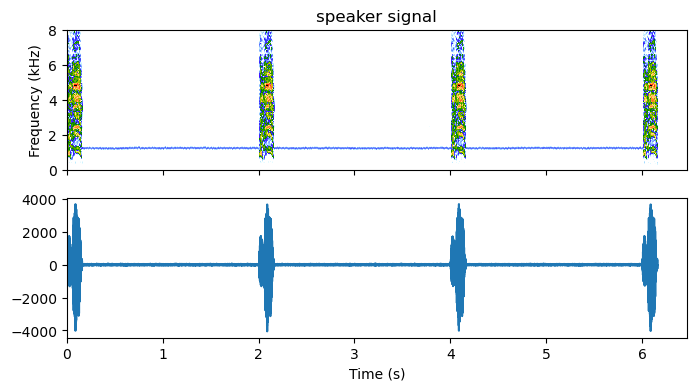

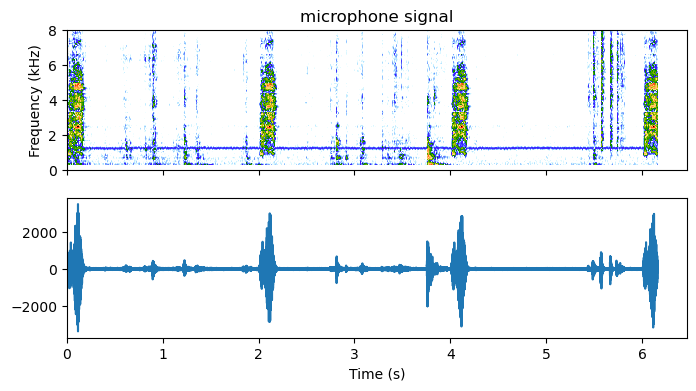

In [14]:
# lets get the 4th trial from the first operant experiment
trial = trials.iloc[3]
print(' ************** 4th trial ***************** ')
plot_trial_spectros(trial)

 ************** 12th trial ***************** 


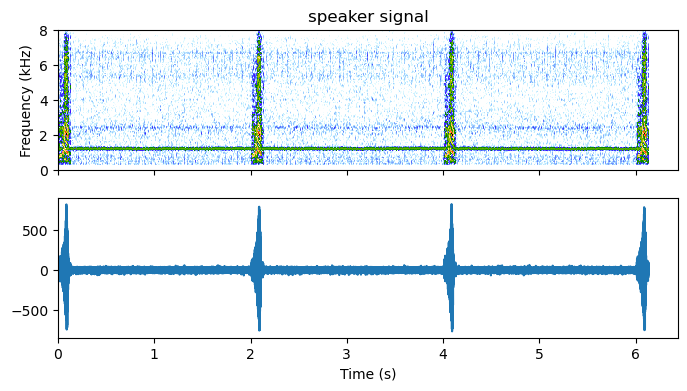

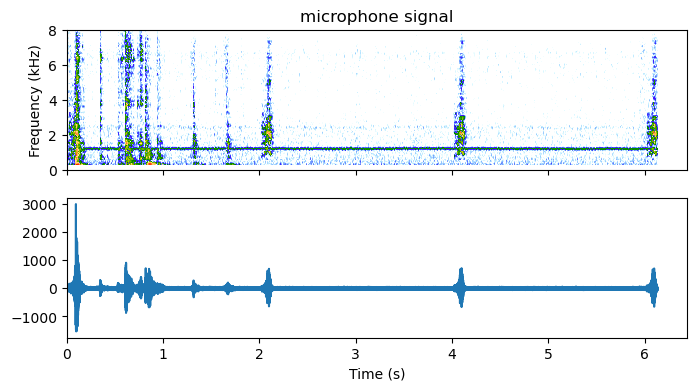

In [15]:
# lets get the 12th trial which is the 1st trial from the second operant experiment
trial = trials.iloc[11]
print(' ************** 12th trial ***************** ')
plot_trial_spectros(trial)

 ************** 121st trial ***************** 


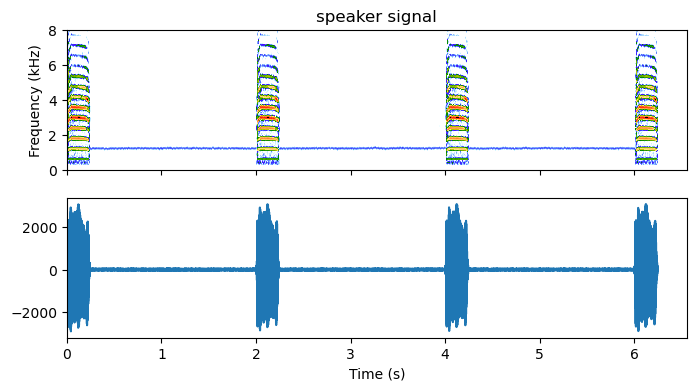

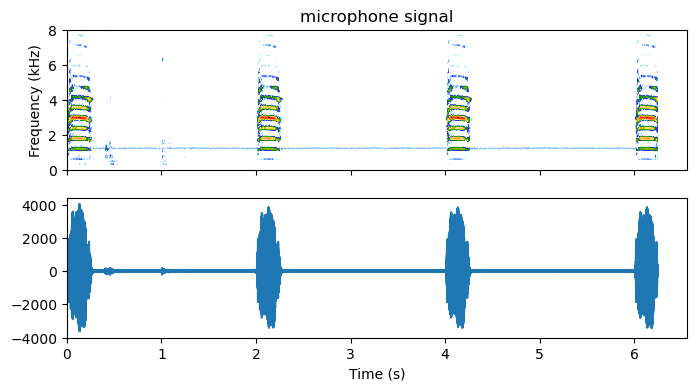

In [16]:
# lets get the 121st trial which is the 111th trial from the second operant experiment before the missing RHD file
trial = trials.iloc[121]
print(' ************** 121st trial ***************** ')
plot_trial_spectros(trial)

 ************** 121st trial ***************** 


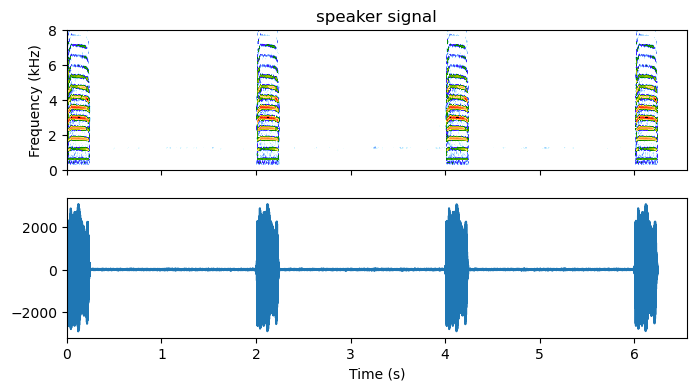

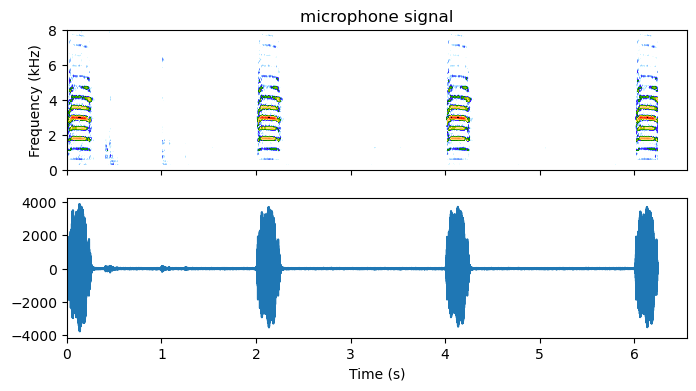

In [17]:
# lets get the 121st trial which is the 111th trial from the second operant experiment before the missing RHD file and remove the annoying 1200Hz contamination
trial = trials.iloc[121]
print(' ************** 121st trial ***************** ')
plot_trial_spectros(trial,1)

 ************** 122nd trial / after missing RHD ***************** 


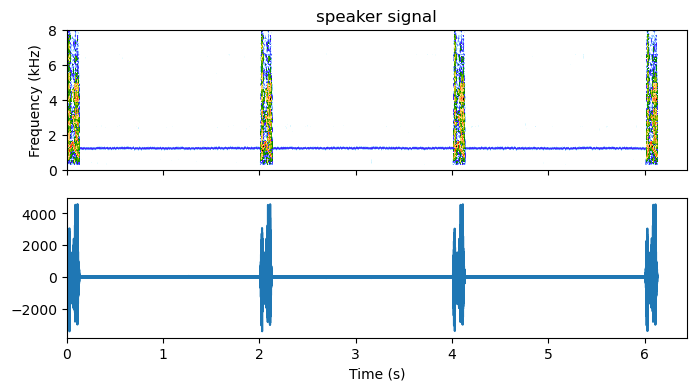

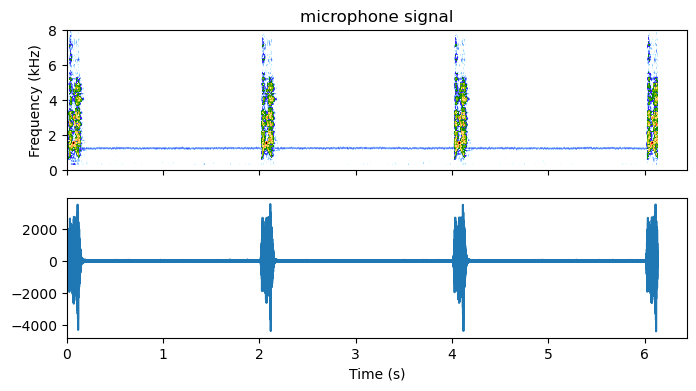

In [18]:
# lets get the 122nd trial which is the 124th trial from the second operant experiment and happens after the missing RHD file
trial = trials.iloc[122]
print(' ************** 122nd trial / after missing RHD ***************** ')
plot_trial_spectros(trial)

In [19]:
trials

,start_time,stop_time,trial_num,experiment_uid,stimuli_path,stimuli_name,bird_name,stim_class,trial_type,response,correct,timeseries
id,,,,,,,,,,,,
0,418.385467,424.658800,1,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_5_GreGre6364_130416-DC-16.wav,GreGre6364,reward,operant,False,True,"[(3137891, 47049, motion pynwb.base.TimeSeries..."
1,495.395067,501.645834,2,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_2_GreWhi1242_130417-DC-02.wav,GreWhi1242,reward,operant,False,True,"[(3715463, 46880, motion pynwb.base.TimeSeries..."
2,545.488833,551.694800,3,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_4_YelGre5275_110616-DC-14.wav,YelGre5275,reward,operant,False,True,"[(4091166, 46545, motion pynwb.base.TimeSeries..."
3,603.538800,609.698200,4,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_6_LblBla4419_130416-DC-35.wav,LblBla4419,reward,operant,False,True,"[(4526541, 46195, motion pynwb.base.TimeSeries..."
4,669.094733,670.697825,5,PurWhi127037F_20250329122721,I:/OperantEphys/PurWhi127037F/OperantExperimen...,DC_Stim_2_GreGre6364_130416-DC-01.wav,GreGre6364,reward,operant,True,False,"[(5018210, 12023, motion pynwb.base.TimeSeries..."
...,...,...,...,...,...,...,...,...,...,...,...,...
557,24856.634900,24862.772733,559,PurWhi127037F_20250329124551,I:/OperantEphys/PurWhi127037F/OperantExperimen...,LT_Stim_6_LblBlu6680_110413-LTC-12.wav,LblBlu6680,nonreward,operant,False,False,"[(186424761, 46034, motion pynwb.base.TimeSeri..."
558,24874.007000,24875.945066,560,PurWhi127037F_20250329124551,I:/OperantEphys/PurWhi127037F/OperantExperimen...,Be_Stim_5_LblBlu2028_110225-Beggseq-02_01.wav,LblBlu2028,nonreward,operant,True,True,"[(186555052, 14535, motion pynwb.base.TimeSeri..."
559,24876.020433,24882.291506,561,PurWhi127037F_20250329124551,I:/OperantEphys/PurWhi127037F/OperantExperimen...,So_Stim_1_RedRas3600_110615-Song-01.wav,RedRas3600,nonreward,operant,True,True,"[(186570153, 47033, motion pynwb.base.TimeSeri..."


In [20]:
units = nwb.units.to_dataframe()
units

,kilosort_dir,kilosort_id,group,ks_x,ks_y,spike_times,electrodes
id,,,,,,,
0,ks4__phy_JEE_20251108/shank_1,47,good,177.772751,107.266350,"[0.5525, 0.5679, 1.2309666666666668, 2.1965333...",location ...
1,ks4__phy_JEE_20251108/shank_1,134,mua,179.257797,245.340958,"[0.08336666666666667, 5.4603, 8.4118, 18.57903...",location ...
2,ks4__phy_JEE_20251108/shank_1,153,good,182.410736,276.335052,"[2.7893666666666665, 2.9239, 5.142666666666667...",location ...
3,ks4__phy_JEE_20251108/shank_1,181,good,168.810959,11.057719,"[3.4804, 3.5350333333333332, 3.551466666666666...",location ...
4,ks4__phy_JEE_20251108/shank_1,185,good,168.784042,10.261288,"[0.8123, 2.1976666666666667, 2.3359, 5.6299666...",location ...
...,...,...,...,...,...,...,...
203,ks4__phy_JEE_20251108/shank_0,741,good,8.029533,153.519348,"[0.015066666666666667, 0.019866666666666668, 0...",location ...
204,ks4__phy_JEE_20251108/shank_0,742,good,16.946568,39.348564,"[0.2514, 0.5006666666666667, 1.050733333333333...",location ...
205,ks4__phy_JEE_20251108/shank_0,743,good,6.766281,97.717705,"[0.7067666666666667, 0.7799333333333334, 0.868...",location ...


# For each trial plot a matrix of the corresponding spike rate activity for any unit, range of units or all units (mua + good)

In [26]:
trials.iloc[121]

start_time                                             10953.511867
stop_time                                                10959.7554
trial_num                                                       111
experiment_uid                         PurWhi127037F_20250329124551
stimuli_path      I:/OperantEphys/PurWhi127037F/OperantExperimen...
stimuli_name                 DC_Stim_10_GreGre6364_130416-DC-13.wav
bird_name                                                GreGre6364
stim_class                                                   reward
trial_type                                                  operant
response                                                      False
correct                                                        True
timeseries        [(82151339, 46826, motion pynwb.base.TimeSerie...
Name: 121, dtype: object

## gather data from all units for trial 121
This take a bit to run and save a large matrix

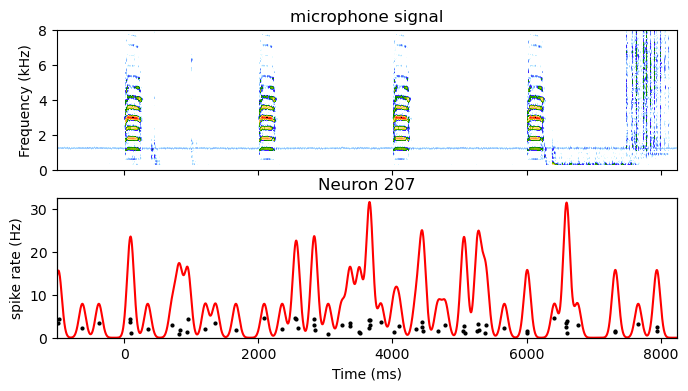

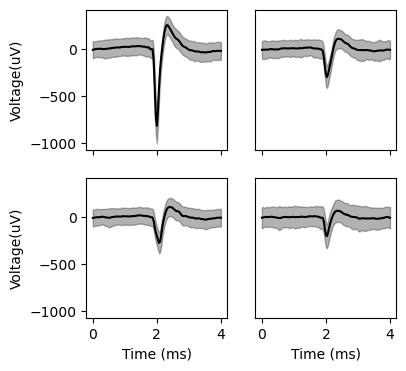

In [ ]:
buffer = [1,2] # in s
kde_width = 50
plotFlag = 1
micFlag = 1
trial_number = 121
trial = trials.iloc[trial_number]
print(' ************** ' + str(trial_number) + 'st trial ***************** ')
neuralpop_data = get_allneural_data_pertrial(nwb, trial,buffer,kde_width, plotFlag, micFlag)

## only gather data from unit 82

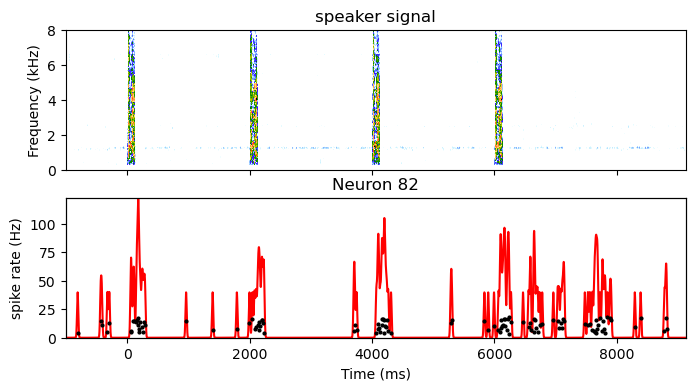

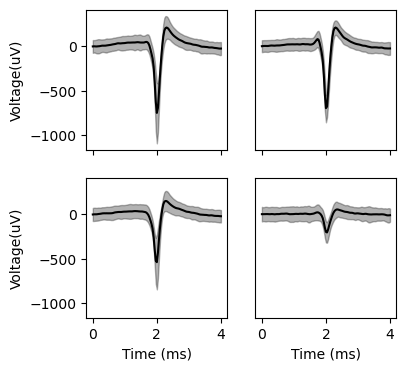

'DC_Stim_1_WhiBlu5698_110329-DC-11.wav'

In [ ]:
buffer = [1,3] # in s
kde_width = 10
plotFlag = 1
micFlag = 0
notchFilterFlag = 1
trial_number = 122
trial = trials.iloc[trial_number]
neuronID = 82 #6, 37, 181
print(' ************** ' + str(trial_number) + 'st trial ***************** ')
neuron82_data = get_allneural_data_pertrial(nwb, trial,buffer,kde_width, plotFlag, micFlag,notchFilterFlag, neuronID)
trial['stimuli_name']

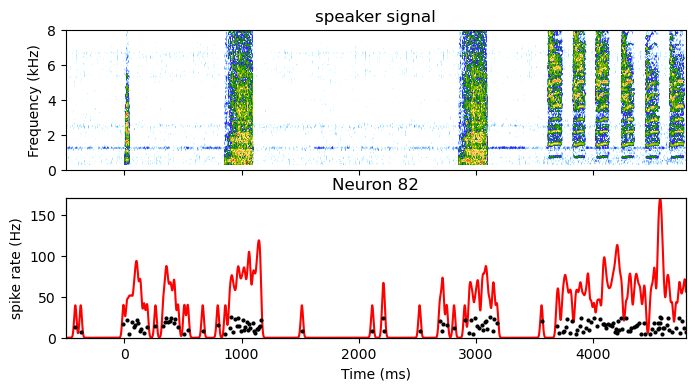

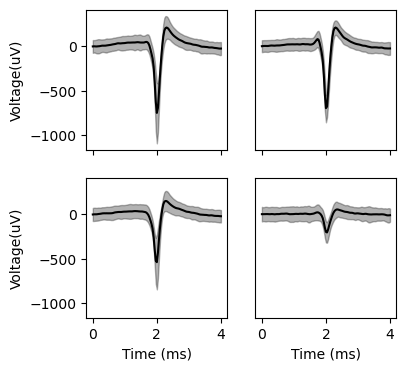

'Tu_Stim_4_GraGra0201_110616-TukC-05.wav'

In [ ]:
buffer = [0.5, 4] # in s
kde_width = 10
plotFlag = 1
micFlag = 0
notchFilterFlag =1
trial_number = 123
trial = trials.iloc[trial_number]
neuronID = 82 #6, 37, 181
print(' ************** ' + str(trial_number) + 'st trial ***************** ')
neuron82_data = get_allneural_data_pertrial(nwb, trial,buffer,kde_width, plotFlag, micFlag,notchFilterFlag, neuronID)
trial['stimuli_name']

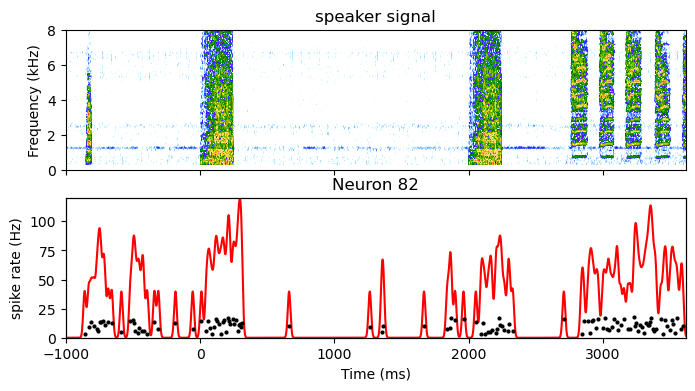

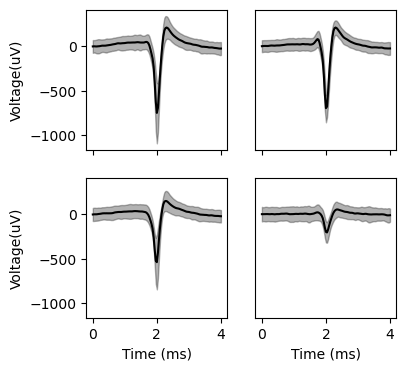

'Ag_Stim_2_WhiBlu4818_110404-AggC-06.wav'

In [ ]:
buffer = [1,1] # in s
kde_width = 10
plotFlag = 1
micFlag = 0
notchFilterFlag = 1
trial_number = 124
trial = trials.iloc[trial_number]
neuronID = 82 #6, 37, 181
print(' ************** ' + str(trial_number) + 'st trial ***************** ')
neuron82_data = get_allneural_data_pertrial(nwb, trial,buffer,kde_width, plotFlag, micFlag, notchFilterFlag, neuronID)
trial['stimuli_name']

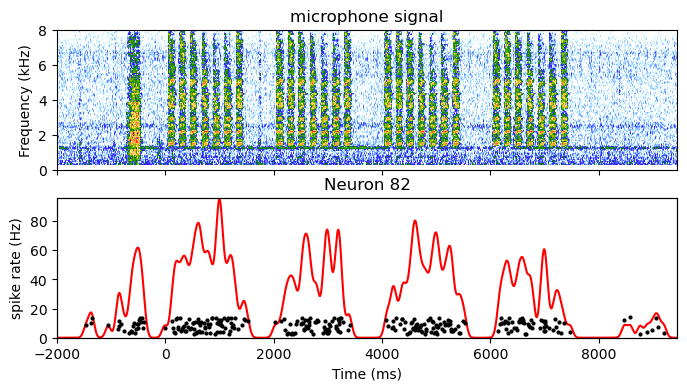

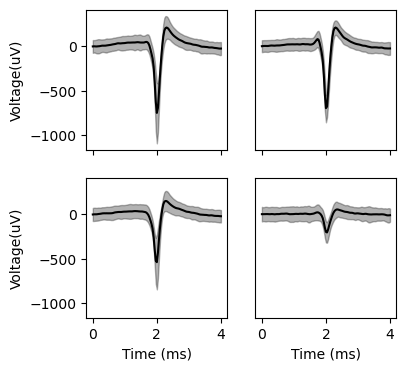

'Be_Stim_4_GraRas1500_110224-Beggseq-02.wav'

In [ ]:
buffer = [2,2] # in s
kde_width = 50
plotFlag = 1
micFlag = 1
notchFilterFlag = 1
trial_number = 125
trial = trials.iloc[trial_number]
neuronID = 82 #6, 37, 181
print(' ************** ' + str(trial_number) + 'st trial ***************** ')
neuron82_data = get_allneural_data_pertrial(nwb, trial,buffer,kde_width, plotFlag, micFlag,notchFilterFlag, neuronID)
trial['stimuli_name']


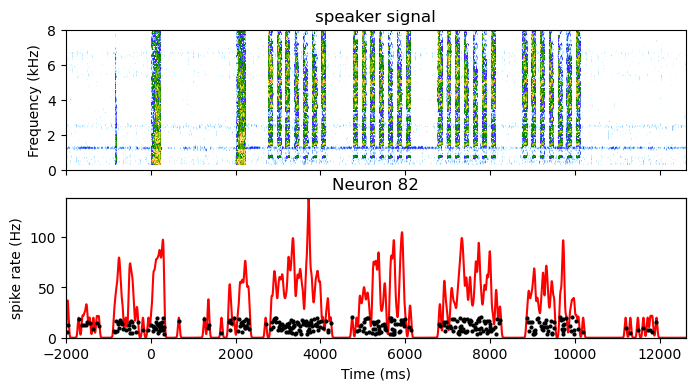

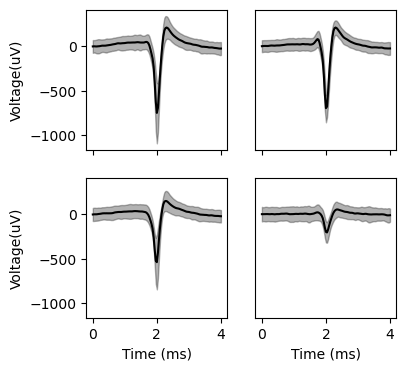

In [ ]:
buffer = [2,10] # in s
kde_width = 20
plotFlag = 1
micFlag = 0
notchFilterFlag =1
trial_number = 124
trial = trials.iloc[trial_number]
neuronID = 82 #6, 37, 181
print(' ************** ' + str(trial_number) + 'st trial ***************** ')
neuron82_data = get_allneural_data_pertrial(nwb, trial,buffer,kde_width, plotFlag, micFlag,notchFilterFlag, neuronID)

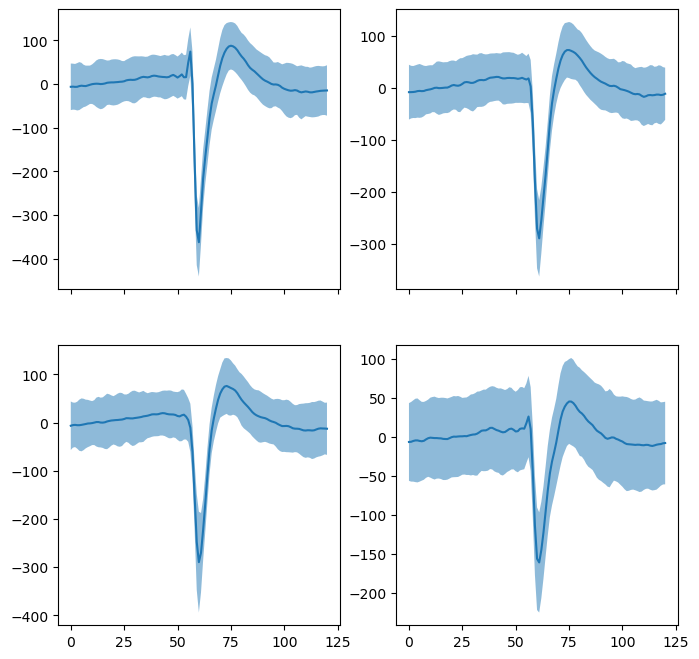

In [521]:
uu=0
fig, axs = plt.subplots(nrows=2, ncols=2, sharex=True, dpi=100, figsize = (8,8))
waveforms = nwb.acquisition['unit_waveforms'].to_dataframe()
for cc, ax in enumerate(axs.flatten()):
    wavemean=waveforms[waveforms.unit_id == uu].waveform_mean[uu][cc,]
    wavesd = waveforms[waveforms.unit_id == uu].waveform_sd[uu][cc,]
    ax.fill_between(np.array(range(0,len(wavemean))), wavemean-wavesd, wavemean+wavesd, alpha = 0.5)
    ax.plot(np.array(range(0,len(wavemean))), wavemean)
plt.show()


# Obtain the biosound acoustic features of Trial 121 call

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
                Bird b'GreGre6364'    Call Type b'DC'


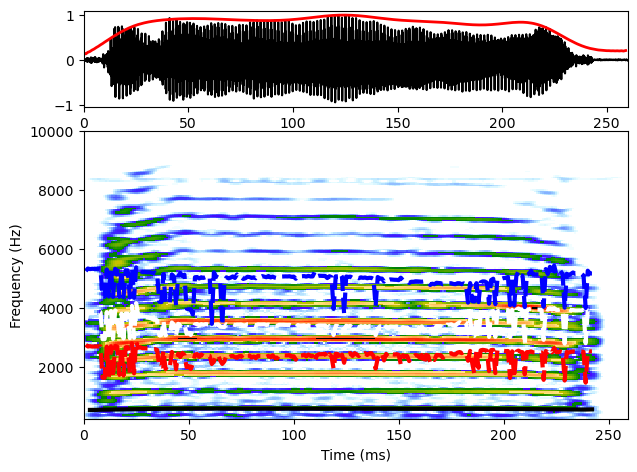

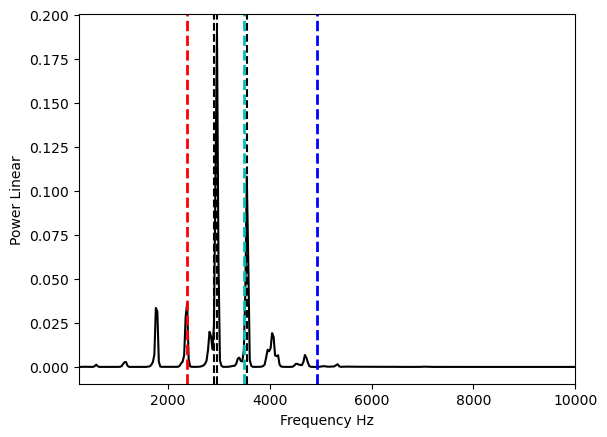

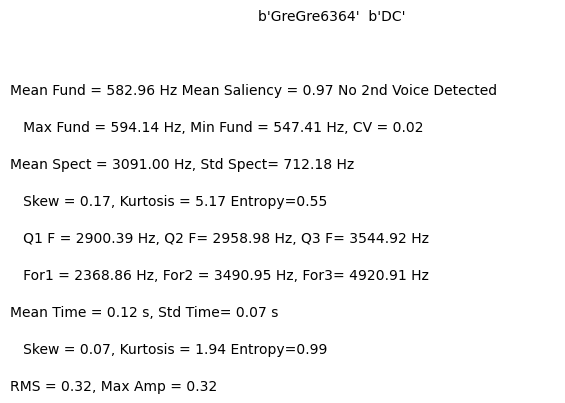

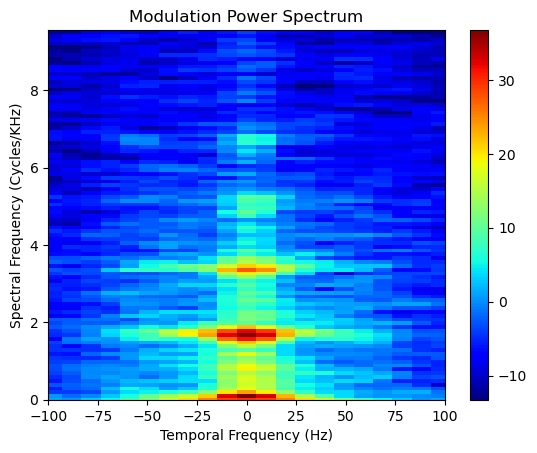

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


In [523]:
trial_number = 121
trial = trials.iloc[trial_number]
# get the audio data for that trial
mic_signal_trial, speaker_signal_trial,rate = get_audio_data(nwb, trial)

# Filter the contaminated 1200Hz
fs = rate
f0 = 1200.0  # Frequency to be removed from signal (Hz)
Q = 20.0  # Quality factor
b, a = iirnotch(f0, Q, fs)
speaker_signal_trial = filtfilt(b, a,speaker_signal_trial)

# restrict the signal to the first 200ms (only one call)
speaker_signal_trial = speaker_signal_trial[0:int(rate*0.26)]

# Normalize if wanted
maxAmp = np.abs(speaker_signal_trial).max() 
    
# Create BioSound Object
myBioSound = BioSound(soundWave=speaker_signal_trial/maxAmp, fs=rate, emitter='GreGre6364', calltype = 'DC')
             
# Calculate the spectrogram and the rms
myBioSound.spectroCalc(spec_sample_rate=1000, freq_spacing = 50, min_freq=0, max_freq=10000)
myBioSound.rms = myBioSound.sound.std() 
       
# Calculate amplitude enveloppe
myBioSound.ampenv(cutoff_freq = 20, amp_sample_rate = 1000)
       
# Calculate the power spectrum
myBioSound.spectrum(f_high=10000)
    
    # Calculate fundamental and related values.  These are the default values.
    # For the estimation of the fundamental, four methods are available: 
    # 'AC' - Peak of the auto-correlation function
    # 'ACA' - Peak of envelope of auto-correlation function 
    # 'Cep' - First peak in cepstrum 
    # 'Stack' - Fitting of harmonic stacks (default - works well for zebra finches)
    
myBioSound.fundest(maxFund = 1500, minFund = 300, lowFc = 200, highFc = 6000, 
                           minSaliency = 0.5, debugFig = 0, 
                           minFormantFreq = 500, maxFormantBW = 500, windowFormant = 0.1,
                           method='Stack')
      
# Calculate the MPS
myBioSound.mpsCalc(window=0.1, Norm = True)
                
print('++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++')
print('                Bird %s    Call Type %s' % (myBioSound.emitter, myBioSound.type))
myBioSound.plot(DBNOISE=50, f_low=250, f_high=10000)  
print('++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++')

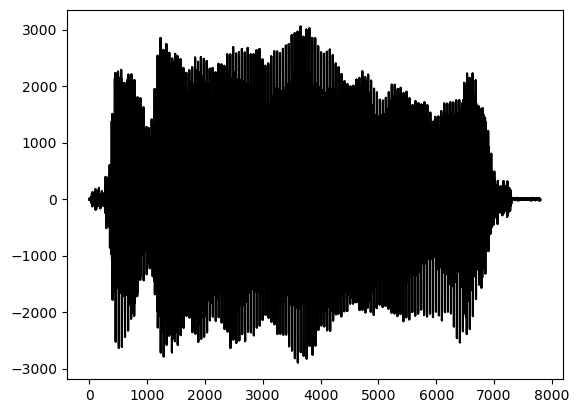

In [525]:
plt.plot(speaker_signal_trial, '-k')
#plt.savefig('/Users/elie/Library/CloudStorage/Box-Box/ERC/WorkingFolder2026/Figures/Trial121_Oscillo.eps')
plt.show()

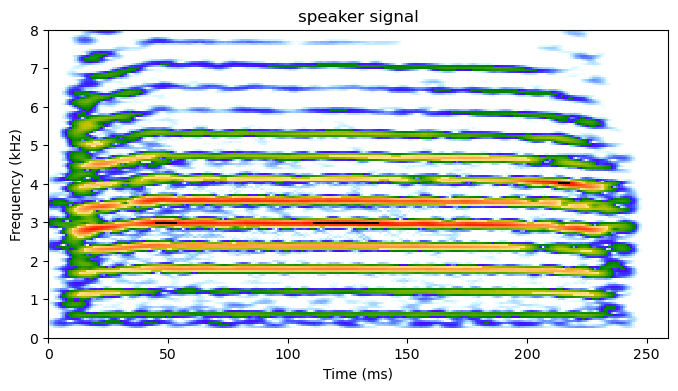

In [534]:
# Spectrogram paramteters.
stim_params = {}
stim_params['fband'] = 50
stim_params['nstd'] = 6
stim_params['high_freq'] = 8000
stim_params['low_freq'] = 250
stim_params['log'] = 1
stim_params['stim_rate'] = 1000  # Sample rate of spectrogram
DBNOISE = 50
# Colormap for plotting spectrograms
spec_colormap()   # defined in sound.py
tfrep = timefreq_raw(speaker_signal_trial, rate, 'ft', params=stim_params)
f, ax1 = plt.subplots(1, 1, sharex=True, dpi=100, figsize = (8,4))
ax1.set_xlabel('Time (ms)')
ax1.set_title('speaker signal')
cmap = plt.get_cmap('SpectroColorMap')
minSpect = tfrep['spec'].max()-DBNOISE
maxB = tfrep['spec'].max()
ax1.imshow(tfrep['spec'], extent=[tfrep['t'][0]*1000, tfrep['t'][-1]*1000, tfrep['f'][0]*1e-3, tfrep['f'][-1]*1e-3],
                aspect='auto', interpolation='nearest', origin='lower', cmap=cmap, vmin=minSpect, vmax=maxB)
ax1.set_ylim(0, 8)
ax1.set_ylabel('Frequency (kHz)')
#plt.savefig('/Users/elie/Library/CloudStorage/Box-Box/ERC/WorkingFolder2026/Figures/Trial121_Spectro.eps')
plt.show()

# Plot all neural data for a given trial

 ************** 122st trial ***************** 
Number of units: 208


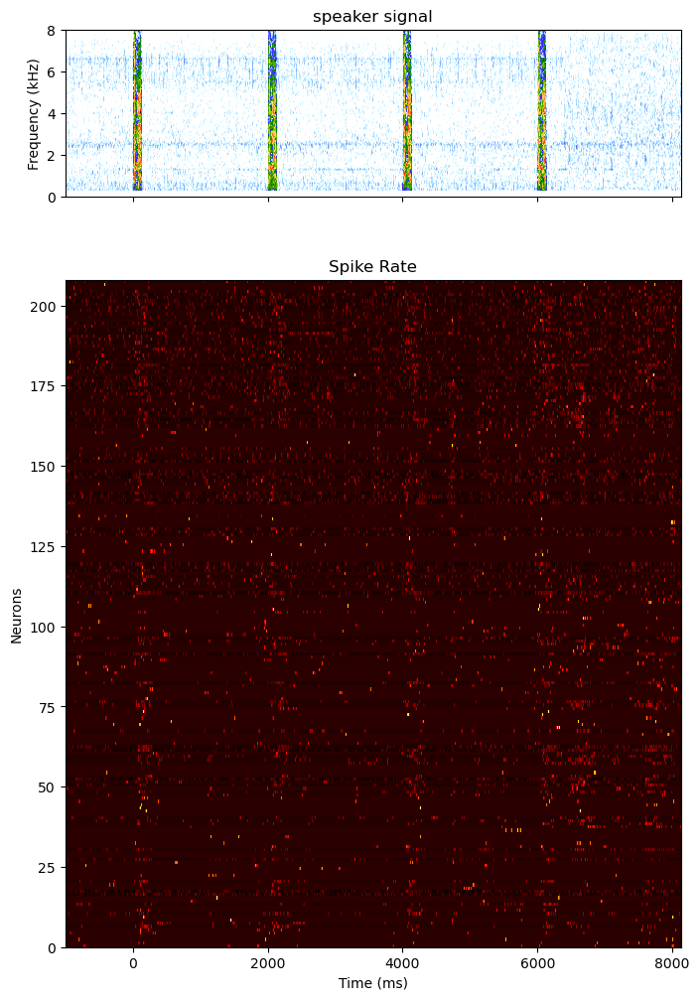

In [539]:
buffer = [1,2] # in s
kde_width = 5
plotFlag = 0
micFlag = 0
trial_number = 122
trial = trials.iloc[trial_number]
print(' ************** ' + str(trial_number) + 'st trial ***************** ')
plot_trial_neuropop(nwb, trial,buffer,kde_width)

 ************** 125st trial ***************** 
Number of units: 208


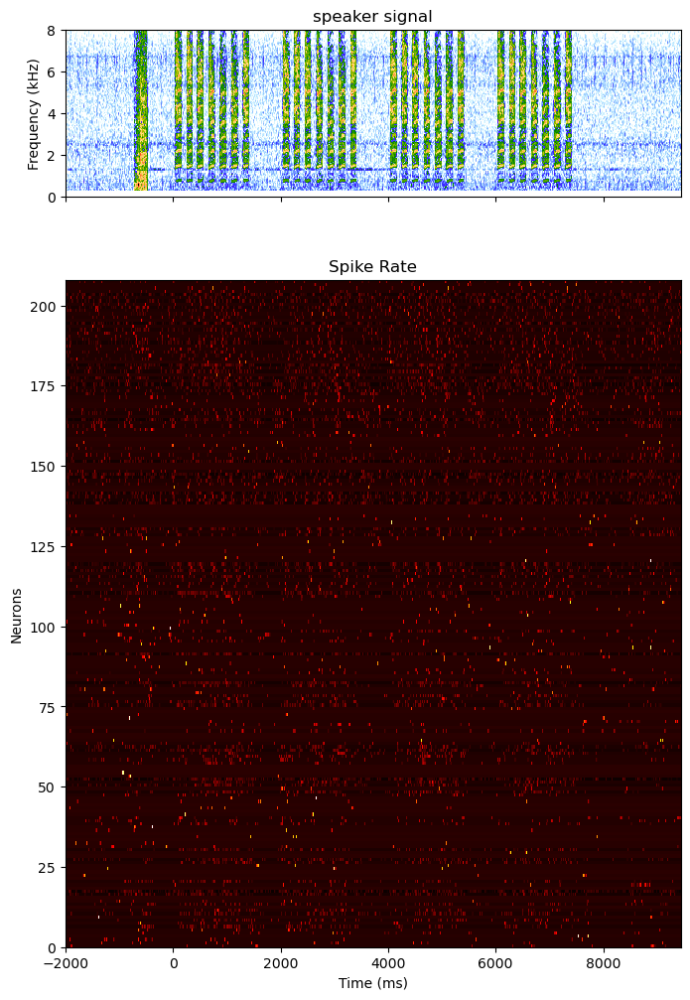

In [540]:

buffer = [2,2] # in s
kde_width = 5
plotFlag = 0
micFlag = 0
trial_number = 125
trial = trials.iloc[trial_number]
print(' ************** ' + str(trial_number) + 'st trial ***************** ')
plot_trial_neuropop(nwb, trial,buffer,kde_width)

# Compile time varying rates for figure in ERC

## identify units with high spike rate during trial 121

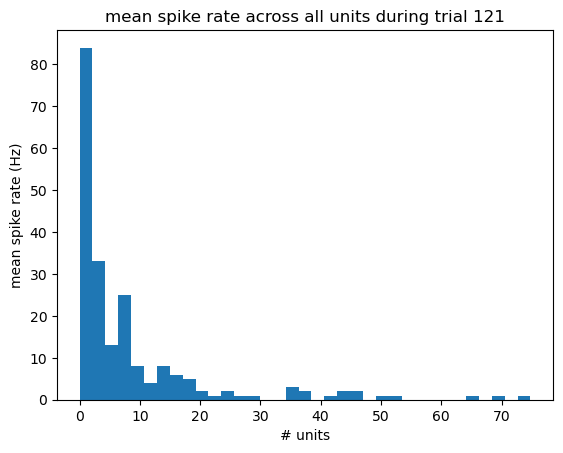

In [ ]:
buffer = [2,2] # in s
kde_width = 50
plotFlag = 0
micFlag = 0
trial_number = 121
trial = trials.iloc[trial_number]
neuralpop_data = get_allneural_data_pertrial(nwb, trial,buffer,kde_width, plotFlag, micFlag)
mean_rate = np.nanmean(neuralpop_data, axis = 1, keepdims=True)
plt.hist(mean_rate,bins = 35,)
plt.ylabel('mean spike rate (Hz)')
plt.xlabel('# units')
plt.title('mean spike rate across all units during trial ' + str(trial_number))
plt.show()




## plot time varying rate of units with minimum spike rate

[95] units out of 208 have a mean rate above 4Hz


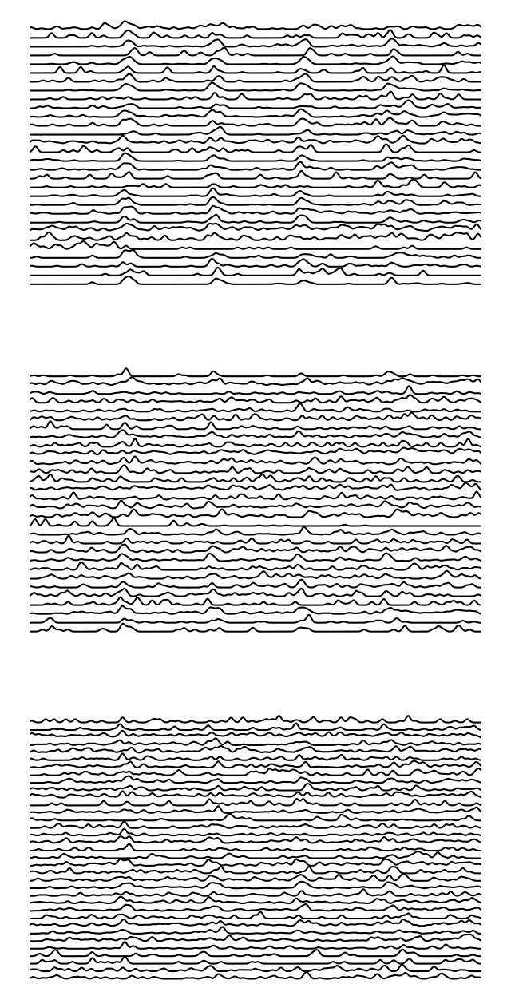

In [546]:
print(str(sum(mean_rate>4)) + ' units out of ' + str(len(mean_rate)) + ' have a mean rate above 4Hz')

ind_high_rate = np.argwhere(mean_rate.flatten()>4).flatten()
neuraldata_4plot = np.array(neuralpop_data)[ind_high_rate]
offset = (np.ones(neuraldata_4plot.shape).T * np.array(range(0,len(ind_high_rate)))).T
neuraldata_4plot = neuraldata_4plot/np.max(neuraldata_4plot, axis = 1,keepdims=True)*0.9 + offset

# figure of time varying rate for spiking units
f, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, dpi=100, figsize = (8,16))
ax1.plot(neuraldata_4plot[0:30,:].T, '-k')
ax1.set_yticks([])
ax1.set_xticks([])
ax1.set_frame_on(False)
ax2.plot(neuraldata_4plot[30:60,:].T, '-k')
ax2.set_yticks([])
ax2.set_xticks([])
ax2.set_frame_on(False)
ax3.plot(neuraldata_4plot[60:95,:].T, '-k')
ax3.set_yticks([])
ax3.set_xticks([])
ax3.set_frame_on(False)
#plt.savefig('/Users/elie/Library/CloudStorage/Box-Box/ERC/WorkingFolder2026/Figures/PopTimeVaryingRate.eps')
plt.show()

# Gather all neural data for all trials and run a PCA to explore Neural spaces

In [9]:
nwb

root pynwb.file.NWBFile at 0x13509760000
Fields:
  acquisition: {
    LFP <class 'pynwb.ecephys.ElectricalSeries'>,
    audcode_events <class 'hdmf.common.table.DynamicTable'>,
    audio <class 'pynwb.base.TimeSeries'>,
    ttl_events <class 'hdmf.common.table.DynamicTable'>,
    unit_waveforms <class 'hdmf.common.table.DynamicTable'>
  }
  devices: {
    cambridge_H10.prb <class 'pynwb.device.Device'>
  }
  electrode_groups: {
    cambridge_H10.prb <class 'pynwb.ecephys.ElectrodeGroup'>
  }
  electrodes: electrodes <class 'pynwb.ecephys.ElectrodesTable'>
  experimenter: ['Thomas, Logan']
  file_create_date: [datetime.datetime(2025, 11, 12, 21, 53, 25, 209277, tzinfo=tzoffset(None, -28800))]
  identifier: c8ef0ee0-0b3f-4be5-bbc9-bbd3347098bc
  institution: University of California, Berkeley
  intervals: {
    operant_trials <class 'pynwb.epoch.TimeIntervals'>,
    playback_trials <class 'pynwb.epoch.TimeIntervals'>,
    pyoperant_experiments <class 'pynwb.epoch.TimeIntervals'>,
    unit_intervals <class 'pynwb.epoch.TimeIntervals'>
  }
  lab: Theunissen Lab
  processing: {
    behavior <class 'pynwb.base.ProcessingModule'>
  }
  session_description: OperantEphys/PurWhi127037F
  session_start_time: 2025-03-29 12:27:05-07:00
  stimulus: {
    Ag_Stim_10_BlaLbl8026_110425-AggC-02.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_10_GraLbl0457_110606-AggC-12.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_10_LblBla4419_130417-Ag-03.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_10_PurRas20dd_110425-AggC-08.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_10_WhiBlu5698_110404-AggC-10.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_10_WhiLbl0010_110606-AggC-13.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_1_WhiBlu4818_110404-AggC-05.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_1_YelOra2575_110622-AggC-04.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_BlaLbl8026_110427-AggC-03.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_GraLbl0457_110606-AggC-06.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_LblBla4419_130416-Ag-02.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_LblRed0613_111006-AggC-25.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_WhiBlu4818_110404-AggC-06.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_WhiBlu5698_110304-AggC-04.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_WhiRas44dd_110616-AggC-08.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_3_BluRas07dd_110601-AggC-20.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_3_PurRas20dd_110425-AggC-09.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_3_WhiBlu5698_110304-AggC-06.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_4_BluRas61dd_110502-AggC-12.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_4_LblBla4419_130417-Ag-03.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_5_GraLbl0457_110606-AggC-09.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_5_LblRed0613_111006-AggC-28.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_5_PurRas20dd_110606-AggC-17.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_5_WhiBlu4818_110404-AggC-07.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_5_WhiLbl0010_110608-AggC-26.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_6_BluRas61dd_110502-AggC-10.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_6_LblRed0613_110921-AggC-08.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_GraLbl0457_110606-AggC-12.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_LblBla4419_130416-Ag-01.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_LblRed0613_111004-AggC-14.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_PurRas20dd_110606-AggC-19.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_WhiBlu5698_110405-AggC-11.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_YelOra2575_110729-AggC-23.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_8_PurRas20dd_110606-AggC-20.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_8_WhiLbl0010_110606-AggC-09.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_8_YelOra2575_110728-AggC-19.wav <class

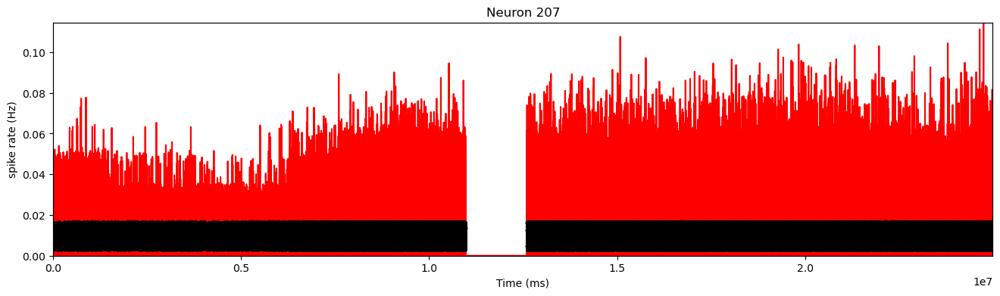

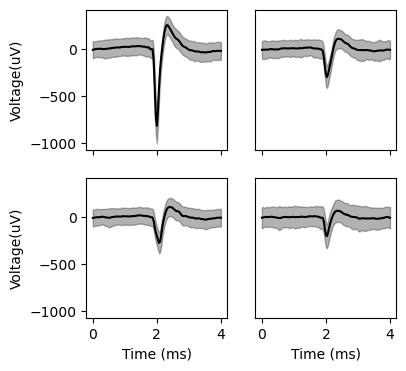

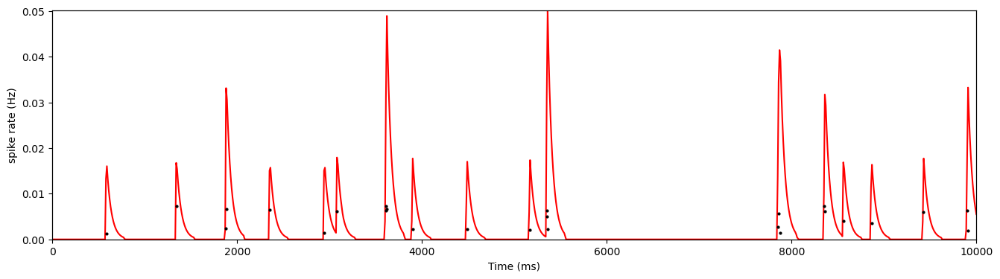

In [19]:
FS = 100 #sampling frequency of neural data in Hz
kde_width = 50 #kde width in ms
neuralpop_data, time = get_allneural_data(nwb,kde_width,FS,1)

In [20]:
neuro_path = '/Users/elie/Library/CloudStorage/Box-Box/ManipBerkeleyZF/neuro_PurWhi_WF/'
filename = '%s/NeuralPop_data_FS%d_kde%d.pkl' % (neuro_path, FS, kde_width)
with open(filename, 'wb') as f:
    pickle.dump({'neuralpop_data': neuralpop_data}, f)

## Load the data of time varying spike rates

In [2]:
neuro_path = '/Users/elie/Library/CloudStorage/Box-Box/ManipBerkeleyZF/neuro_PurWhi_WF/'
filename = '%s/NeuralPop_data.pkl' % (neuro_path)
with open(filename, 'rb') as file:
    neuralpop_data = pickle.load(file)

In [3]:
neuralpop_data = neuralpop_data['neuralpop_data']

In [4]:
neuralpop_data.T.shape

(24990001, 208)

In [13]:
# Run PCA on the dataset, first identify the best dimensions
Dims = np.arange(1,4,1)
Dims = np.append(Dims, np.arange(5,208,5))
PCA_VarExp = list()
for dim in Dims:
    print('running PCA with ' + str(dim) + 'dimensions')
    # run a PCA with dim dimensions on all the dataset
    pca = PCA(n_components=dim)
    pca.fit(neuralpop_data.T)
    #Y_all_r = pca.transform(neuralpop_data.T)
    print ('Variance explained is %.2f%%' % (sum(pca.explained_variance_ratio_)*100.0))
    PCA_VarExp.append(sum(pca.explained_variance_ratio_)*100.0)

running PCA with 1dimensions
Variance explained is 23.68%
running PCA with 2dimensions
Variance explained is 31.05%
running PCA with 3dimensions
Variance explained is 36.51%
running PCA with 5dimensions
Variance explained is 44.76%
running PCA with 10dimensions
Variance explained is 56.55%
running PCA with 15dimensions
Variance explained is 63.31%
running PCA with 20dimensions
Variance explained is 68.15%
running PCA with 25dimensions
Variance explained is 71.90%
running PCA with 30dimensions
Variance explained is 74.88%
running PCA with 35dimensions
Variance explained is 77.50%
running PCA with 40dimensions
Variance explained is 79.82%
running PCA with 45dimensions
Variance explained is 81.91%
running PCA with 50dimensions
Variance explained is 83.73%
running PCA with 55dimensions
Variance explained is 85.37%
running PCA with 60dimensions
Variance explained is 86.90%
running PCA with 65dimensions
Variance explained is 88.23%
running PCA with 70dimensions
Variance explained is 89.42%
r

Text(0, 0.5, 'Variance explained (%)')

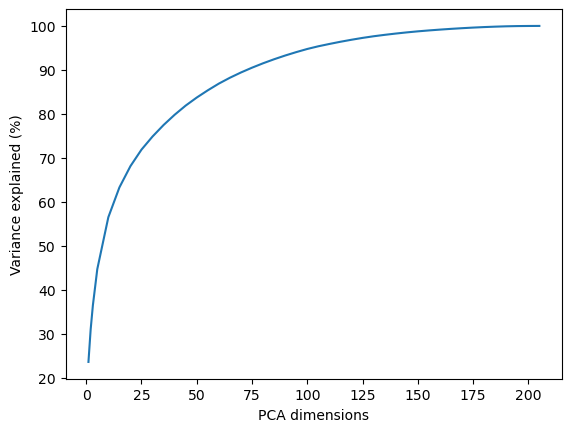

In [19]:
plt.plot(Dims,PCA_VarExp)
plt.xlabel('PCA dimensions')
plt.ylabel('Variance explained (%)')

Text(0, 0.5, 'Variance explained')

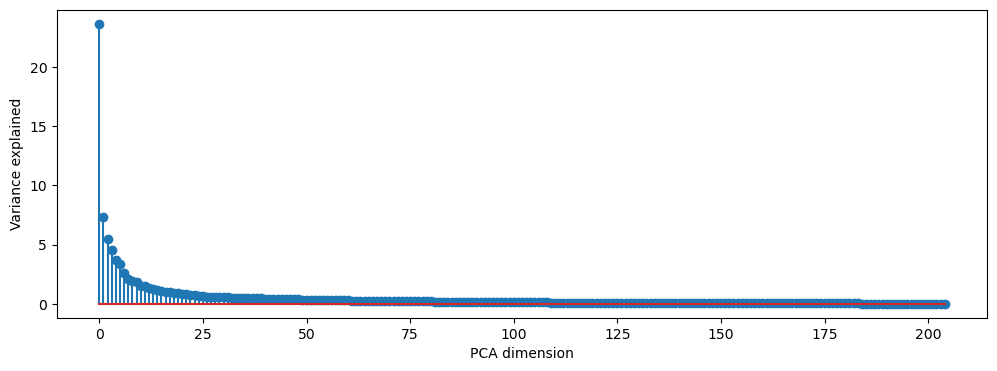

In [28]:
fig0, (ax0) = plt.subplots(1, 1, sharex=True, dpi=100, figsize = (12,4))
ax0.stem(pca.explained_variance_ratio_*100)
ax0.set_xlabel('PCA dimension')
ax0.set_ylabel('Variance explained')

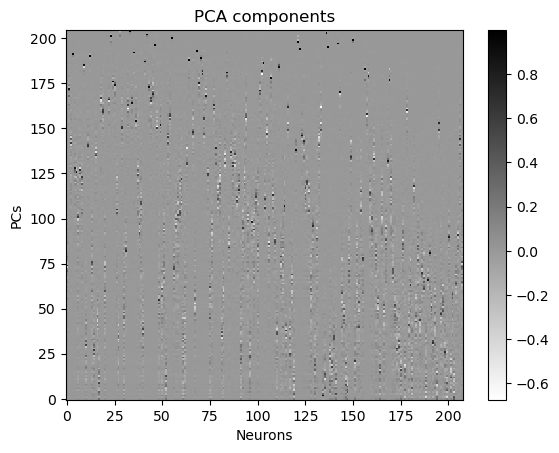

In [32]:
im1 = plt.imshow(pca.components_,
                aspect='auto', interpolation='none', cmap='binary', origin='lower')
plt.ylabel('PCs')
plt.title('PCA components')
plt.xlabel('Neurons')
plt.colorbar(im1)


Try to zscore the neural data before running PCA. PCA by default only center the data

In [5]:
print('calculating STD for each neuron')
std_neuro = np.nanstd(neuralpop_data, axis = 1, keepdims = True)
std_neuro[std_neuro==0] = 1
print('calculating mean for each neuron')
mean_neuro = np.nanmean(neuralpop_data, axis = 1, keepdims=True)

calculating STD for each neuron
calculating mean for each neuron


In [6]:
mean_neuro.shape

(208, 1)

In [7]:
std_neuro.shape

(208, 1)

In [8]:
neuralpop_data[10,:]

array([0.        , 0.        , 0.        , ..., 0.02183083, 0.02139855,
       0.02097483], shape=(24990001,))

In [9]:
for n in range(neuralpop_data.shape[0]):
    neuralpop_data[n,:] -= mean_neuro[n]
    neuralpop_data[n,:] /= std_neuro[n]

In [10]:
neuralpop_data[10,:]

array([-0.72935972, -0.72935972, -0.72935972, ...,  0.79429462,
        0.76412424,  0.73455127], shape=(24990001,))

In [12]:
pca = PCA(n_components=200)
pca.fit(neuralpop_data.T)
#Y_all_r = pca.transform(neuralpop_data.T)
print ('Variance explained is %.2f%%' % (sum(pca.explained_variance_ratio_)*100.0))

Variance explained is 98.82%


Text(0, 0.5, 'Variance explained zscored neural data per neuron')

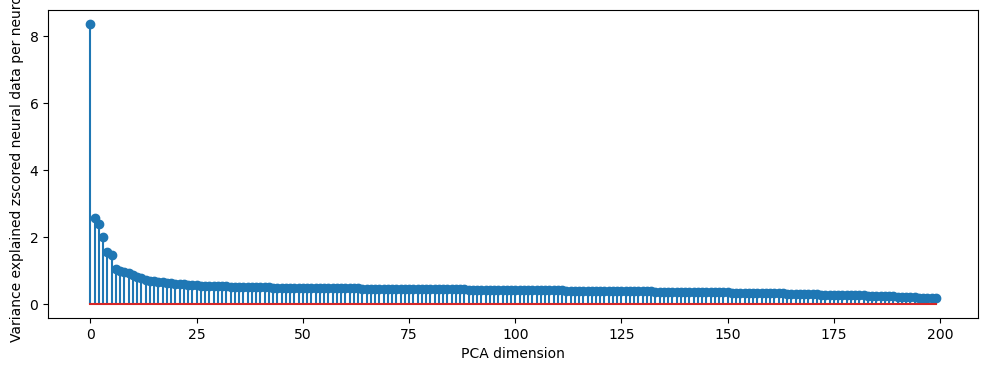

In [13]:

fig0, (ax0) = plt.subplots(1, 1, sharex=True, dpi=100, figsize = (12,4))
ax0.stem(pca.explained_variance_ratio_*100)
ax0.set_xlabel('PCA dimension')
ax0.set_ylabel('Variance explained zscored neural data per neuron')

Text(0, 0.5, 'Variance explained (%)')

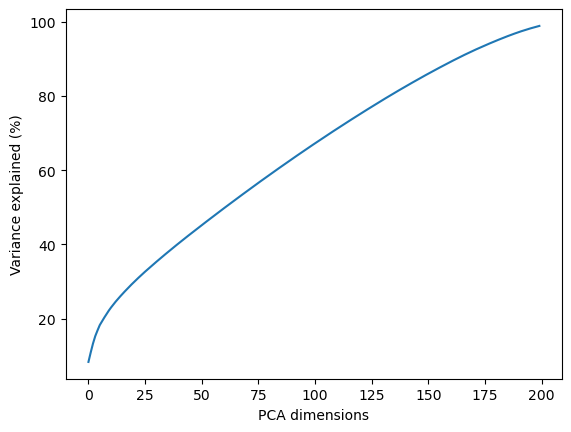

In [14]:
plt.plot(np.cumsum(pca.explained_variance_ratio_*100))
plt.xlabel('PCA dimensions')
plt.ylabel('Variance explained (%)')

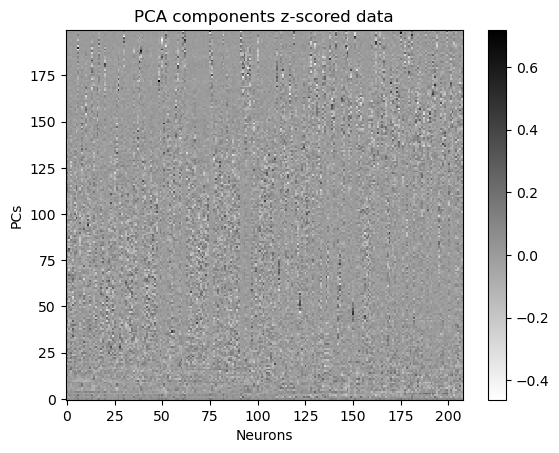

In [15]:
im2 = plt.imshow(pca.components_,
                aspect='auto', interpolation='none', cmap='binary', origin='lower')
plt.ylabel('PCs')
plt.title('PCA components z-scored data')
plt.xlabel('Neurons')
plt.colorbar(im2)

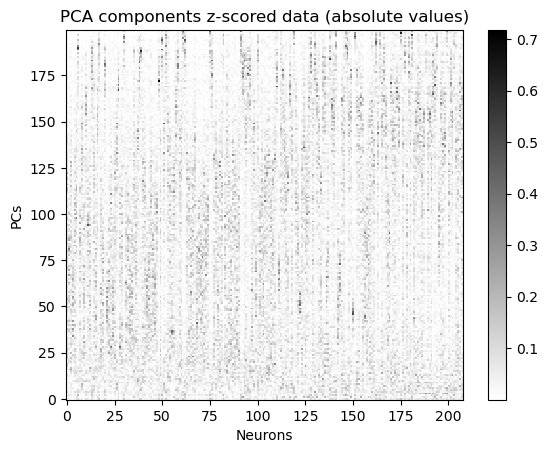

In [16]:
im3 = plt.imshow(np.abs(pca.components_),
                aspect='auto', interpolation='none', cmap='binary', origin='lower')
plt.ylabel('PCs')
plt.title('PCA components z-scored data (absolute values)')
plt.xlabel('Neurons')
plt.colorbar(im3)

# Find periods of active pecking as opposed to resting periods

##              plot the interval between start times across all trials

In [19]:
np.array(trials.start_time.iloc[1:]).shape

(561,)

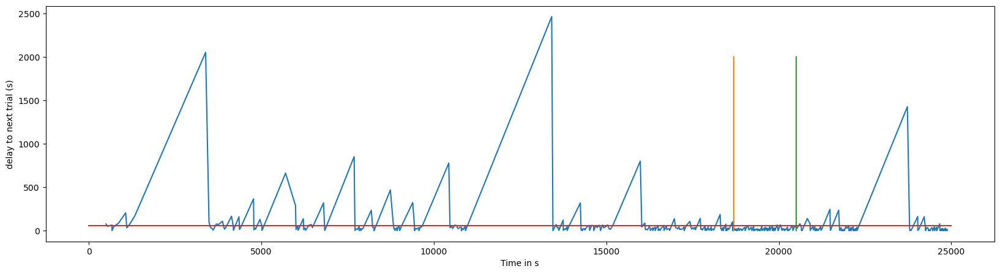

In [20]:
Start_zone = 18700
Stop_zone = 20500
plt.figure(figsize=(20,5))
plt.plot(np.array(trials.start_time.iloc[1:]), np.array(trials.start_time.iloc[1:]) - np.array(trials.start_time.iloc[0:-1]))
plt.xlabel('Time in s')
plt.ylabel('delay to next trial (s)')
plt.plot([Start_zone, Start_zone], [0, 2000]) # good onset section
plt.plot([Stop_zone, Stop_zone], [0, 2000]) # good offset section
plt.plot([0,25000], [60, 60]) # horizontal line shows intertrial intervals of less than 1min

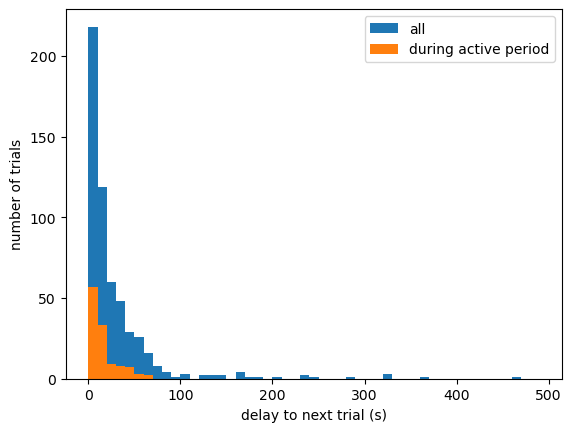

In [21]:
Trial1_zone = int(trials[trials.start_time>Start_zone].index[0])
Triallast_zone = int(trials[trials.start_time<Stop_zone].index[-1])
plt.figure()
plt.hist(np.array(trials.start_time.iloc[1:]) - np.array(trials.start_time.iloc[0:-1]), bins=np.arange(0, 500, 10), range=(0,500), label="all")
plt.hist(np.array(trials.start_time.iloc[(Trial1_zone +1):Triallast_zone]) - np.array(trials.start_time.iloc[Trial1_zone:(Triallast_zone-1)]), bins=np.arange(0, 500, 10),range=(0,500), label="during active period")
plt.xlabel('delay to next trial (s)')
plt.ylabel('number of trials')
plt.legend()

In [22]:
Trial2_zone = int(trials[trials.start_time>Start_zone].index[1])
Trial3_zone = int(trials[trials.start_time>Start_zone].index[2])
Trial4_zone = int(trials[trials.start_time>Start_zone].index[3])
Trial5_zone = int(trials[trials.start_time>Start_zone].index[4])
Trial6_zone = int(trials[trials.start_time>Start_zone].index[5])
Trial7_zone = int(trials[trials.start_time>Start_zone].index[6])
Trial8_zone = int(trials[trials.start_time>Start_zone].index[7])
Trial9_zone = int(trials[trials.start_time>Start_zone].index[8])
Trial10_zone = int(trials[trials.start_time>Start_zone].index[9])
Trial11_zone = int(trials[trials.start_time>Start_zone].index[10])
Triallast_zone = int(trials[trials.start_time<20280].index[-1])
Triallast2_zone = int(trials[trials.start_time<20280].index[-2])
Triallast3_zone = int(trials[trials.start_time<20280].index[-3])
Triallast4_zone = int(trials[trials.start_time<20280].index[-4])
Triallast5_zone = int(trials[trials.start_time<20280].index[-5])

print('This is the number of stitches that would have to be done if we were only to select sections of times where the bird is iddled for less than 100s: ' + str(sum((np.array(trials.start_time.iloc[1:]) - np.array(trials.start_time.iloc[0:-1]))>100)))

print('Time of first trial in that zone: ' + str(trials.start_time.iloc[(Trial1_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Trial1_zone)]))
print('Time of second trial in that zone: ' + str(trials.start_time.iloc[(Trial2_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Trial2_zone)]))
print('Time of third trial in that zone: ' + str(trials.start_time.iloc[(Trial3_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Trial3_zone)]))
print('Time of fourth trial in that zone: ' + str(trials.start_time.iloc[(Trial4_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Trial4_zone)]))
print('Time of fifth trial in that zone: ' + str(trials.start_time.iloc[(Trial5_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Trial5_zone)]))
print('Time of sixth trial in that zone: ' + str(trials.start_time.iloc[(Trial6_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Trial6_zone)]))
print('Time of seventh trial in that zone: ' + str(trials.start_time.iloc[(Trial7_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Trial7_zone)]))
print('Time of eighth trial in that zone: ' + str(trials.start_time.iloc[(Trial8_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Trial8_zone)]))
print('Time of ninth trial in that zone: ' + str(trials.start_time.iloc[(Trial9_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Trial9_zone)]))
print('Time of tenth trial in that zone: ' + str(trials.start_time.iloc[(Trial10_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Trial10_zone)]))
print('Time of 11th trial in that zone: ' + str(trials.start_time.iloc[(Trial11_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Trial11_zone)]))


print('Time of last trial in that zone: ' + str(trials.start_time.iloc[(Triallast_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Triallast_zone)]))
print('Time of one but last trial in that zone: ' + str(trials.start_time.iloc[(Triallast2_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Triallast2_zone)]))
print('Time of 2 but last trial in that zone: ' + str(trials.start_time.iloc[(Triallast3_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Triallast3_zone)]))
print('Time of 3 but last trial in that zone: ' + str(trials.start_time.iloc[(Triallast4_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Triallast4_zone)]))
print('Time of 4 but last trial in that zone: ' + str(trials.start_time.iloc[(Triallast5_zone)]) +  ' -> ' + str(trials.stop_time.iloc[(Triallast5_zone)]))

This is the number of stitches that would have to be done if we were only to select sections of times where the bird is iddled for less than 100s: 32
Time of first trial in that zone: 18700.523166666666 -> 18706.718166666666
Time of second trial in that zone: 18724.538833333332 -> 18730.93766633333
Time of third trial in that zone: 18734.489133333333 -> 18740.73573333333
Time of fourth trial in that zone: 18742.540766666665 -> 18749.686399666665
Time of fifth trial in that zone: 18760.871666666666 -> 18762.209686666665
Time of sixth trial in that zone: 18762.329333333335 -> 18768.420666333335
Time of seventh trial in that zone: 18782.3431 -> 18784.578167
Time of eighth trial in that zone: 18784.643 -> 18787.27401
Time of ninth trial in that zone: 18787.329733333332 -> 18791.06274133333
Time of tenth trial in that zone: 18791.1625 -> 18792.527495
Time of 11th trial in that zone: 18792.6202 -> 18793.983012
Time of last trial in that zone: 20277.8098 -> 20283.194851
Time of one but last t

## extract spike rate during this active period

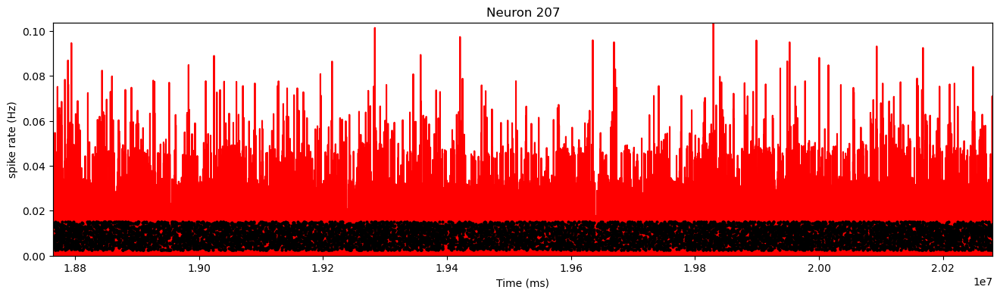

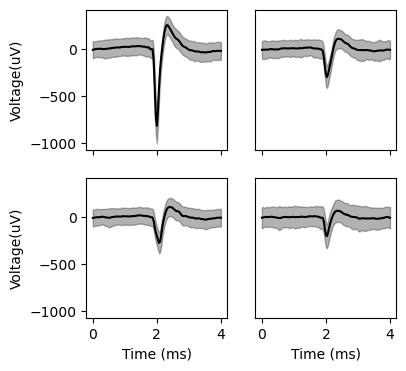

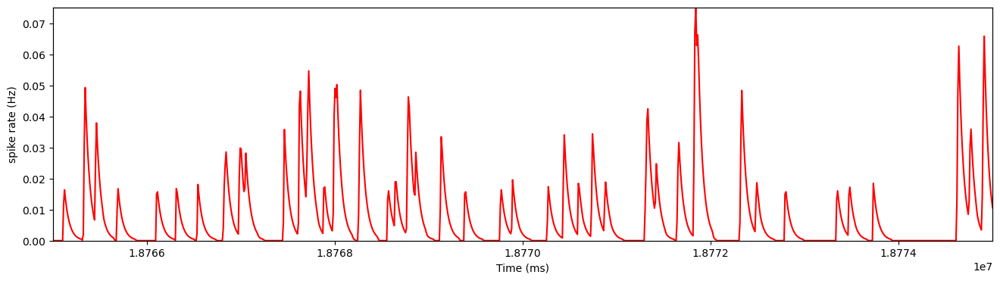

In [105]:
Time_section = (Start_zone, Stop_zone)
FS = 100 #sampling frequency of neural data in Hz
kde_width = 50 #kde width in ms
neuralpop_data, time = get_allneural_data_timesection(nwb, kde_width = kde_width, FS=FS, PlotFlag=1, NeuronID = [], Time_section = Time_section)

In [106]:
neuro_path = '/Users/elie/Library/CloudStorage/Box-Box/ManipBerkeleyZF/neuro_PurWhi_WF/'
filename = '%s/NeuralPop_activePeriod_data_FS%d_kde%d.pkl' % (neuro_path, FS, kde_width)
with open(filename, 'wb') as f:
    pickle.dump({'neuralpop_data': neuralpop_data, 'time': time}, f)

## extract spike count during this active period

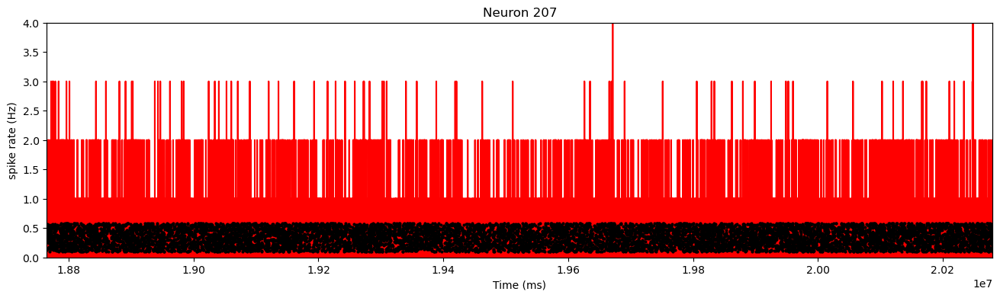

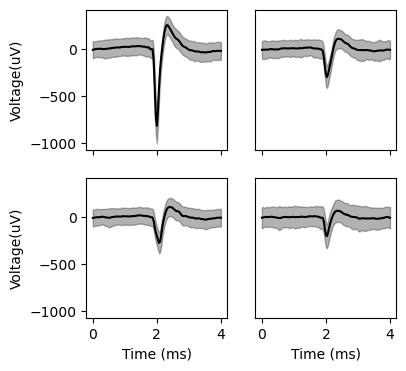

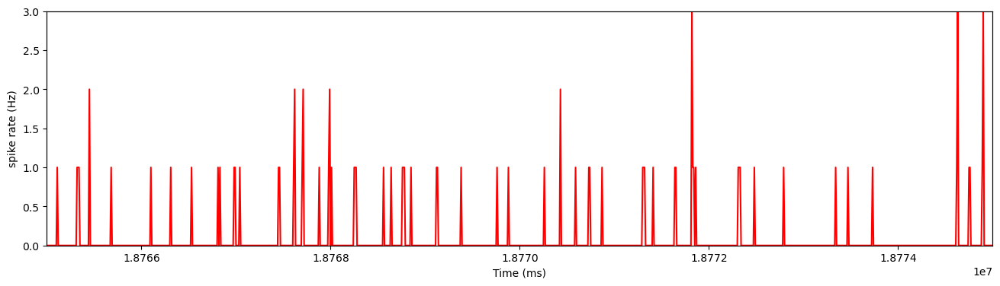

In [27]:
Time_section = (Start_zone, Stop_zone)
FS = 100 #sampling frequency of neural data in Hz
kde_width = [] # spike count so no kde kernel
neuralpop_data, time = get_allneural_data_timesection(nwb, kde_width = kde_width, FS=FS, PlotFlag=1, NeuronID = [], Time_section = Time_section)

In [48]:
neuro_path = '/Users/elie/Library/CloudStorage/Box-Box/ManipBerkeleyZF/neuro_PurWhi_WF/'
filename = '%s/NeuralPop_activePeriod_countData_FS%d.pkl' % (neuro_path, FS)
with open(filename, 'wb') as f:
    pickle.dump({'neuralpop_data': neuralpop_data, 'time': time}, f)

In [40]:
print('onset time of the selected section: ' + str(time[0]/1000) + 's')
print('offset time of the selected section: ' + str(time[-1]/1000) + 's') 

onset time of the selected section: 18765.0s
offset time of the selected section: 20279.99s


## Extract behavioral data for that section

In [23]:
Start_zone = 18700
Stop_zone = 20500

In [52]:
Stimuli = '/users/elie/Library/CloudStorage/GoogleDrive-julie.elie@berkeley.edu/Shared drives/Theunissen Lab Data/Chronic Neural Data Sets/OperantEphys/PurWhi127037F/Stimuli/20250329/PurWhi127037F_20250329_20250329_065746_testVCAT_4repeat_Stims.txt'
Time_section = (Start_zone, Stop_zone)
FS = 100 #sampling frequency of neural data and behavioral in Hz
sensor_data, reward_data, ct_data, audio_data, time, ct_dict = get_operantbehavior_data_timesection(nwb, Stimuli, FS=FS, PlotFlag=0, Time_section = Time_section)

Behavioral data of operant task are extracted for valid intervals of neural activity
calculate tmps of the microphone data projected in PCA space
Calculating tmps 0.0% progress
Processing trial [279]
Processing trial [280]
Processing trial [281]
Processing trial [282]
Processing trial [283]
Processing trial [284]
Processing trial [285]
Processing trial [286]
Processing trial [287]
Processing trial [288]
Processing trial [289]
Processing trial [290]
Processing trial [291]
Processing trial [292]
Processing trial [293]
Processing trial [294]
Processing trial [295]
Processing trial [296]
Processing trial [297]
Processing trial [298]
Processing trial [299]
Processing trial [300]
Processing trial [301]
Processing trial [302]
Processing trial [303]
Processing trial [304]
Processing trial [305]
Processing trial [306]
Processing trial [307]
Processing trial [308]
Processing trial [309]
Processing trial [310]
Processing trial [311]
Processing trial [312]
Processing trial [313]
Processing trial [

In [53]:
list( ct_dict.keys())
np.array(range(0,len(ct_dict.keys())+1))

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

In [57]:
time.shape

(1, 151500)

In [67]:
audio_data[0].shape

(151501, 200)

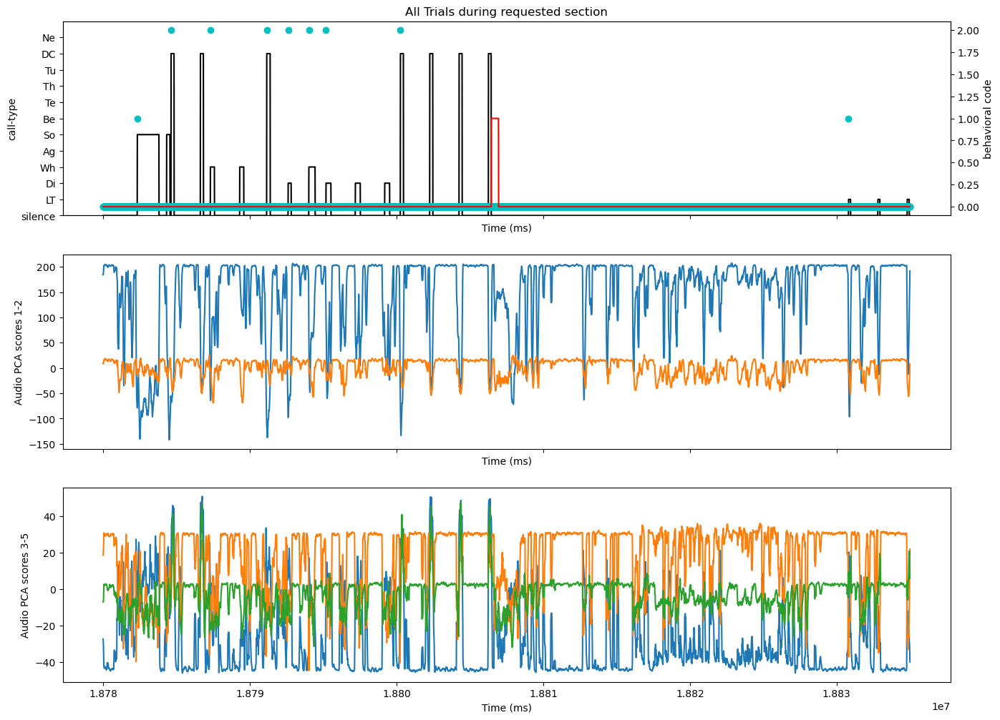

In [ ]:
# of the behavioral data output
section_plot = [15,70] # in s
fig1, (ax1,ax3, ax4) = plt.subplots(3, 1, sharex=True, dpi=100, figsize = (16,12))
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('call-type')
ax1.set_yticks(np.array(range(0,len(ct_dict.keys())+1)))
ax1.set_yticklabels(['silence'] + list( ct_dict.keys()))
ax1.set_ylim([0,12])
ax1.plot(time[0][(section_plot[0]*FS):(section_plot[1]*FS)] ,ct_data[0][(section_plot[0]*FS):(section_plot[1]*FS)], 'k-') # code for call-type
ax2 = ax1.twinx()
ax2.plot(time[0][(section_plot[0]*FS):(section_plot[1]*FS)],sensor_data[0][(section_plot[0]*FS):(section_plot[1]*FS)], 'c', marker='o', markersize=6, linestyle='None') # pecking event
ax2.plot(time[0][(section_plot[0]*FS):(section_plot[1]*FS)],reward_data[0][(section_plot[0]*FS):(section_plot[1]*FS)], 'r-') # reward vector

ax2.set_ylabel('behavioral code')
ax1.set_title('All Trials during requested section')

ax3.set_xlabel('Time (ms)')
ax3.set_ylabel('Audio PCA scores 1-2')
ax3.plot(time[0][(section_plot[0]*FS):(section_plot[1]*FS)], audio_data[0][(section_plot[0]*FS):(section_plot[1]*FS), 0:2])

ax4.set_xlabel('Time (ms)')
ax4.set_ylabel('Audio PCA scores 3-5')
ax4.plot(time[0][(section_plot[0]*FS):(section_plot[1]*FS)], audio_data[0][(section_plot[0]*FS):(section_plot[1]*FS), 2:5])



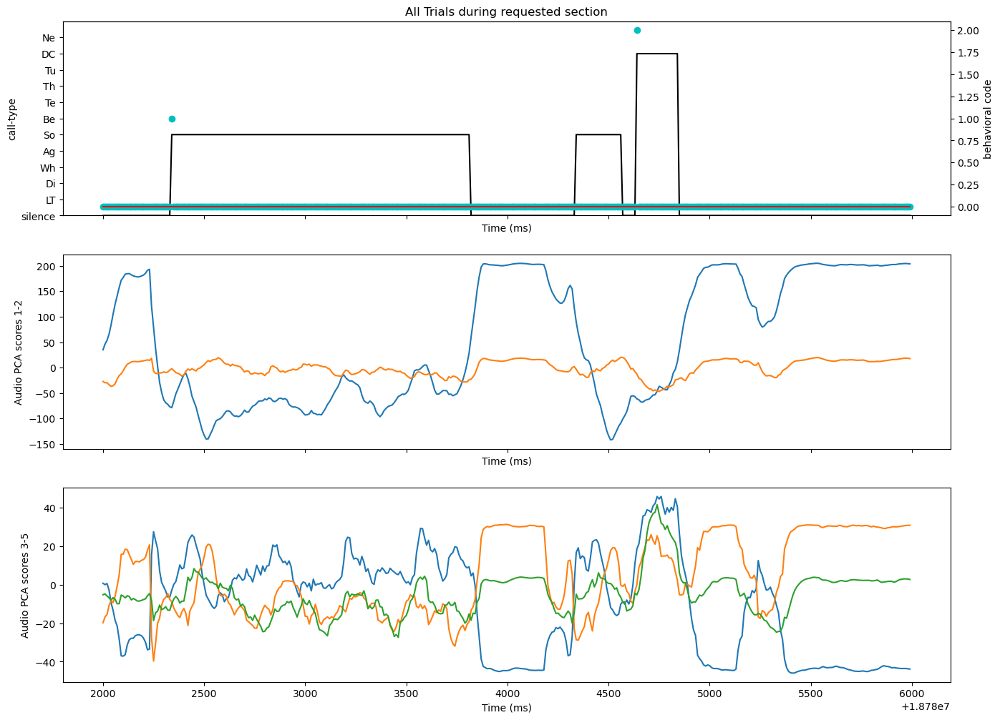

In [65]:
# of the behavioral data output
section_plot = [17,21] # in s
fig1, (ax1,ax3, ax4) = plt.subplots(3, 1, sharex=True, dpi=100, figsize = (16,12))
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('call-type')
ax1.set_yticks(np.array(range(0,len(ct_dict.keys())+1)))
ax1.set_yticklabels(['silence'] + list( ct_dict.keys()))
ax1.set_ylim([0,12])
ax1.plot(time[0][(section_plot[0]*FS):(section_plot[1]*FS)] ,ct_data[0][(section_plot[0]*FS):(section_plot[1]*FS)], 'k-') # code for call-type
ax2 = ax1.twinx()
ax2.plot(time[0][(section_plot[0]*FS):(section_plot[1]*FS)],sensor_data[0][(section_plot[0]*FS):(section_plot[1]*FS)], 'c', marker='o', markersize=6, linestyle='None') # pecking event
ax2.plot(time[0][(section_plot[0]*FS):(section_plot[1]*FS)],reward_data[0][(section_plot[0]*FS):(section_plot[1]*FS)], 'r-') # reward vector

ax2.set_ylabel('behavioral code')
ax1.set_title('All Trials during requested section')

ax3.set_xlabel('Time (ms)')
ax3.set_ylabel('Audio PCA scores 1-2')
ax3.plot(time[0][(section_plot[0]*FS):(section_plot[1]*FS)], audio_data[0][(section_plot[0]*FS):(section_plot[1]*FS), 0:2])

ax4.set_xlabel('Time (ms)')
ax4.set_ylabel('Audio PCA scores 3-5')
ax4.plot(time[0][(section_plot[0]*FS):(section_plot[1]*FS)], audio_data[0][(section_plot[0]*FS):(section_plot[1]*FS), 2:5])

In [68]:
neuro_path = '/Users/elie/Library/CloudStorage/Box-Box/ManipBerkeleyZF/neuro_PurWhi_WF/'
filename = '%s/Behavior_activePeriod_FS%d.pkl' % (neuro_path, FS)
# not that because of rounding issues, audio_data is longer by one row (time point), and we also want to have time in columns and features in rows, hence the selection below when saving ( (1, 151501, 200) -> (1, 200, 151500))
with open(filename, 'wb') as f:
    pickle.dump({'time': time, 'sensor_data':sensor_data, 'reward_data': reward_data, 'ct_data': ct_data, 'audio_data': np.ascontiguousarray(audio_data[:, :-1, :].transpose(0, 2, 1)), 'ct_dict':ct_dict}, f)


# Plots for grants

 ************** 87st trial ***************** 
Number of units: 208


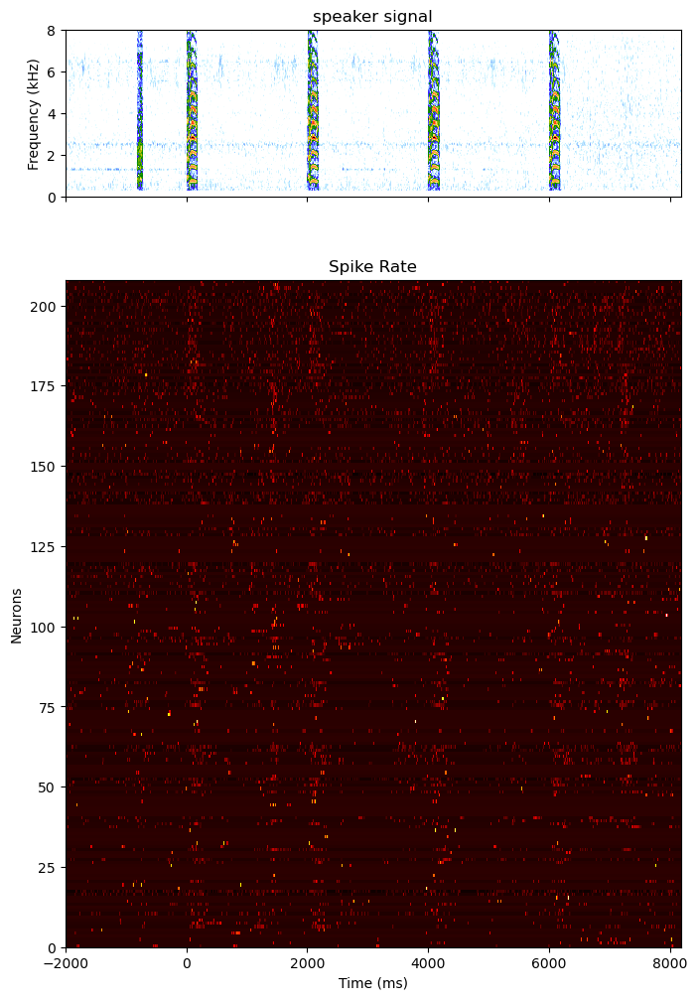

In [ ]:
buffer = [2,2] # in s
kde_width = 5
plotFlag = 0
micFlag = 0
trial_number = 87
trial = trials.iloc[trial_number]
print(' ************** ' + str(trial_number) + 'st trial ***************** ')
plot_trial_neuropop(nwb, trial,buffer,kde_width,micFlag)

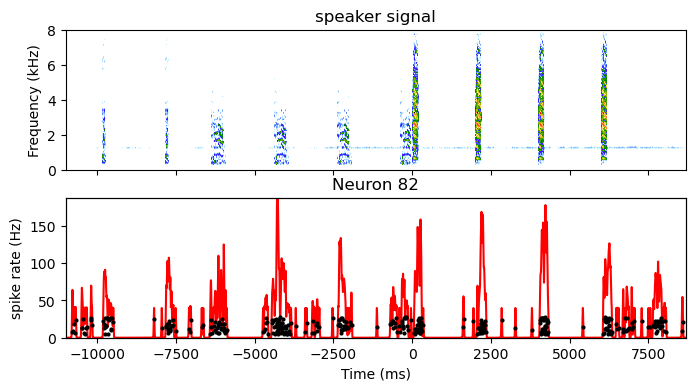

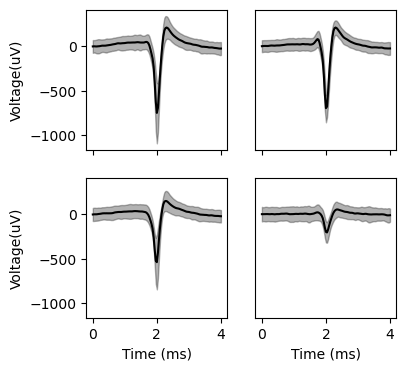

'DC_Stim_4_WhiRas44dd_110620-DC-26.wav'

In [ ]:
buffer = [11, 2.5] # in s
kde_width = 10
plotFlag = 1
micFlag = 0
notchFilterFlag = 1
trial_number = 131
trial = trials.iloc[trial_number]
neuronID = 82 #6, 37, 181
print(' ************** ' + str(trial_number) + 'st trial ***************** ')
neuralpop_data = get_allneural_data_pertrial(nwb, trial,buffer,kde_width, plotFlag, micFlag,notchFilterFlag, neuronID)
trial['stimuli_name']

 ************** 131st trial ***************** 
Number of units: 87


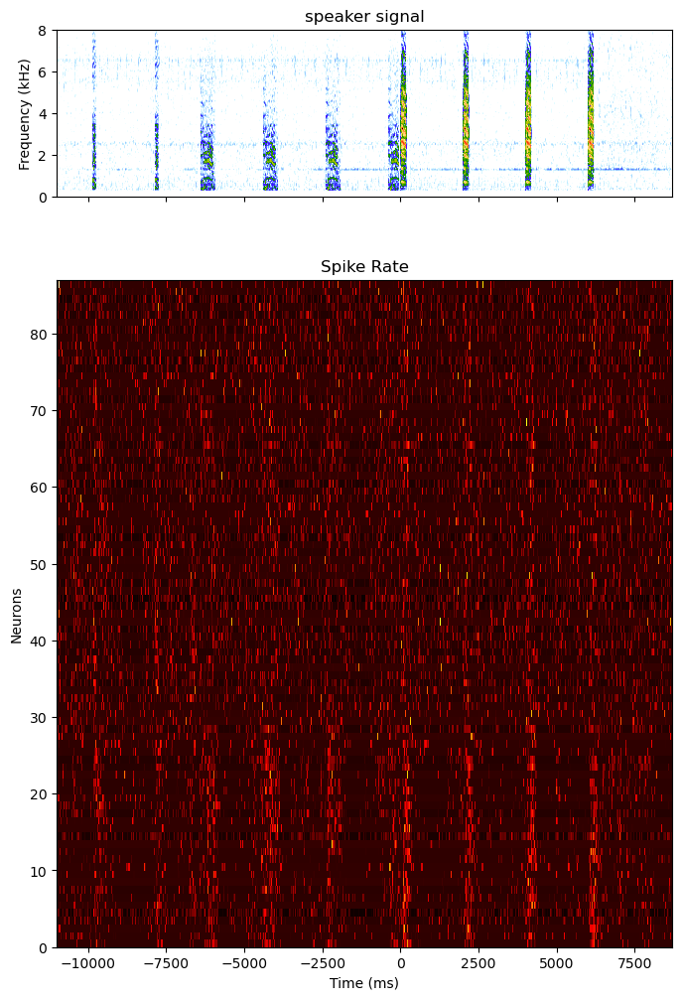

In [ ]:
buffer = [11,2.5] # in s
kde_width = 5
micFlag = 0
trial_number = 131
notchFilterFlag = 1
min_rate = 4
trial = trials.iloc[trial_number]
print(' ************** ' + str(trial_number) + 'st trial ***************** ')
plot_trial_neuropop(nwb, trial,buffer,kde_width,micFlag,notchFilterFlag,min_rate)

In [ ]:
neuralpop_data = get_allneural_data_pertrial(nwb, trial,buffer,kde_width, plotFlag, micFlag)
mean_rate = np.nanmean(neuralpop_data, axis = 1, keepdims=True)
np.argwhere(mean_rate.flatten()>4).flatten()

array([  6,  10,  13,  16,  17,  20,  27,  30,  38,  39,  40,  48,  50,
        51,  52,  57,  58,  61,  62,  67,  75,  76,  81,  82,  91,  95,
        96,  98, 110, 112, 113, 115, 117, 118, 119, 128, 129, 130, 138,
       139, 140, 141, 144, 145, 146, 147, 148, 151, 152, 153, 155, 162,
       163, 164, 166, 167, 171, 172, 173, 174, 175, 176, 177, 179, 180,
       181, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 194, 196,
       197, 198, 199, 200, 201, 202, 203, 204, 207])

In [ ]:
audcode_events = nwb.acquisition['audcode_events'].to_dataframe()
session_start = nwb.session_start_time.replace(tzinfo=None)
audcode_events['datetime'] = [session_start + timedelta(seconds=x) for x in audcode_events['timestamp']]
trial_blocks = np.split(audcode_events, np.where(np.diff(audcode_events.trial) !=1)[0]+1)
trial_blocks_n = np.split(audcode_events,np.where(audcode_events.trial == 1)[0][1:])

/Users/elie/miniconda3/envs/neuro/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [ ]:
trial_blocks_n[1]

,timestamp,code,object,action,repetition,trial,md5,datetime
id,,,,,,,,
11,1161.066900,Speaqueu00000001a1fd260d8c0f4787f7494c2597a4d074,Spea,queu,0,1,a1fd260d8c0f4787f7494c2597a4d074,2025-03-29 12:46:26.066900
12,1332.030733,Speaqueu00000002149a1133d9e760f50c7e7c297da49515,Spea,queu,0,2,149a1133d9e760f50c7e7c297da49515,2025-03-29 12:49:17.030733
13,3384.292167,Speaqueu00000003976337726a3290e442c7603bedcbb53b,Spea,queu,0,3,976337726a3290e442c7603bedcbb53b,2025-03-29 13:23:29.292167
14,3482.672433,Speaqueu00000004eb4dab9a5f1477172091e9b8cf46d20c,Spea,queu,0,4,eb4dab9a5f1477172091e9b8cf46d20c,2025-03-29 13:25:07.672433
15,3521.306533,Speaqueu00000005b2e8b0fc004a4d85e2eb289b17114776,Spea,queu,0,5,b2e8b0fc004a4d85e2eb289b17114776,2025-03-29 13:25:46.306533
...,...,...,...,...,...,...,...,...
557,24856.634900,Speaqueu00000559f460074244dcc8c8bdc4006212260049,Spea,queu,0,559,f460074244dcc8c8bdc4006212260049,2025-03-29 19:21:21.634900
558,24874.007000,Speaqueu000005605bb8c855592c30eee8cca748fed185a1,Spea,queu,0,560,5bb8c855592c30eee8cca748fed185a1,2025-03-29 19:21:39.007000
559,24876.020433,Speaqueu000005611a8bf12dbe711e7546326ebe6ff31719,Spea,queu,0,561,1a8bf12dbe711e7546326ebe6ff31719,2025-03-29 19:21:41.020433


In [ ]:
trial_block_starts = [x.datetime.iloc[0] for x in trial_blocks]
trial_block_ends = [x.datetime.iloc[-1] for x in trial_blocks]

In [ ]:
trial_block = trial_blocks[1]
audcode_event = trial_block[trial_block.trial == 100].iloc[0]

In [ ]:
audcode_event

timestamp                                         10717.937533
code          Speaqueu00000100b224297ca77e1dbc6ba318db785490e7
object                                                    Spea
action                                                    queu
repetition                                                   0
trial                                                      100
md5                           b224297ca77e1dbc6ba318db785490e7
datetime                            2025-03-29 15:25:42.937533
Name: 110, dtype: object

In [ ]:
dig_codes[110:130]

NameError: name 'dig_codes' is not defined

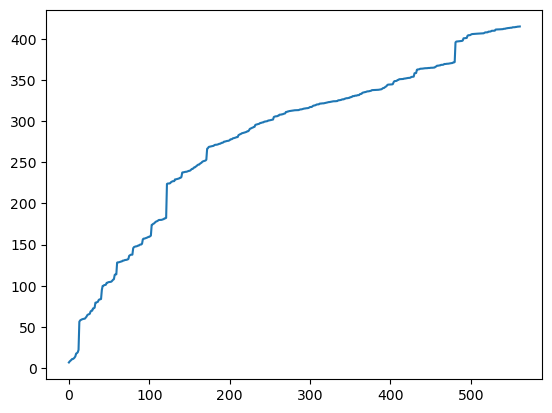

In [ ]:
plt.plot(dig_codes['timestamp'].values/60)

This code takes the spikes data from all the units from 1 day and create a h5py file containing :
- Cluster id 
- Baseline (spike rate for 1 second long bins)
- Baseline times (associated start times of the bins)
- Trial response (spike rate for the 500 ms at the beginning of a playback/trial, sorted by their start time from all_trials)
- Z Scores (Trial response/Baseline, Zscored for each units)

It's also plotting and saving the following plots :
- a plot of baseline and response to playback and operant across the day for each unit

In [ ]:
site_day = 4
bird = 'RedXXX19XXM'
loc = 'local'

if bird == 'RedXXX19XXM':
    if loc == 'corvus' :
        bird_basepath = '/mnt/Data/aude/songephys-data/OperantEphys/RedXXX19XXM/sites/'
        stim_base = '/auto/zdrive/aude/Stage_PLR1/PeckingTest/EphysShaping_2IND/'
        fig_basesave = '/auto/zdrive/aude/Stage_PLR1/Analysis/SingleUnits/RedXXX19XXM'

    elif loc == 'local' :
        bird_basepath = "C:\\Users\\auded\\Documents\\EphysData\\RedXXX19XXM"
        stim_base = "C:\\Users\\auded\\Documents\\EphysShaping_2IND"
        fig_basesave = "C:\\Users\\auded\\Documents\\Analysis\\SingleUnits\\RedXXX19XXM"

    if site_day == 1:
        site = os.path.join(bird_basepath, 'RedXXX19XXM__241122_135651_site1_op_pb/RedXXX19XXM__241122_135651_site1_op_pb.nwb')
        h5py_savepath = os.path.join(bird_basepath,  'RedXXX19XXM__241122_135651_site1_op_pb')
        stim_basepath = os.path.join(stim_base,  'day1-TEvALL')
        fig_basesavepath = os.path.join(fig_basesave,  'site1')

    elif site_day == 2 :
        site = os.path.join(bird_basepath,  'RedXXX19XXM__241123_085354_site2_op_pb/RedXXX19XXM__241123_085354_site2_op_pb_ks4_yartsev.nwb')
        h5py_savepath = os.path.join(bird_basepath,  'RedXXX19XXM__241123_085354_site2_op_pb')
        stim_basepath = os.path.join(stim_base,  'day3-DCLL')
        fig_basesavepath = os.path.join(fig_basesave,  'site2')
        
    elif site_day == 3:
        site = os.path.join(bird_basepath,  'RedXXX19XXM__241124_074736_site3_op_pb/RedXXX19XXM__241124_074736_site3_op_pb_ks4_final.nwb')
        h5py_savepath = os.path.join(bird_basepath,  'RedXXX19XXM__241124_074736_site3_op_pb')
        stim_basepath = os.path.join(stim_base,  'day2-THvALL')
        fig_basesavepath = os.path.join(fig_basesave,  'site3')

    elif site_day == 4:
        site = os.path.join(bird_basepath,  'RedXXX19XXM__241125_084952_site4_op_pb/RedXXX19XXM__241125_084952_site4_op_pb_ks4_yartsev.nwb')
        h5py_savepath =os.path.join(bird_basepath,  'RedXXX19XXM__241125_084952_site4_op_pb')
        stim_basepath = os.path.join(stim_base,  'day1-TEvALL')
        fig_basesavepath = os.path.join(fig_basesave,  'site4')

    elif site_day == 5:
        site = os.path.join(bird_basepath,  'RedXXX19XXM__241126_092207_site5_op_pb/RedXXX19XXM__241126_092207_site5_op_pb_ks4_yartsev.nwb')
        h5py_savepath =os.path.join(bird_basepath,  'RedXXX19XXM__241126_092207_site5_op_pb')
        stim_basepath = os.path.join(stim_base,  'day1-TEvALL') ## WHAT WAS IT ???
        fig_basesavepath = os.path.join(fig_basesave,  'site5')

In [ ]:
# nwb_file_path = site
# output_path = site

# """
# Add unit valid intervals to the NWB file.

# Parameters:
# - nwb_file_path: str, path to the input NWB file.
# - output_path: str, path to save the updated NWB file.

# Returns:
# - None
# """
# with pynwb.NWBHDF5IO(nwb_file_path, 'r+') as nwb_io:
#     nwb = nwb_io.read()
#     all_units = nwb.units.to_dataframe()

#     # Create the intervals table
#     unit_intervals = TimeIntervals(
#         name="unit_intervals",
#         description="Valid intervals for each unit"
#     )
#     unit_intervals.add_column(
#         name='unit_id',
#         description='The ID of the unit in the NWB file that this interval corresponds to',
#         data=np.array([], dtype=int)
#     )

#     for uid, unit in all_units.iterrows():
#         spike_times = nwb.units['spike_times'][uid]

#         # Get total recording time rounded to the nearest second
#         tot_time = int(nwb.acquisition['LFP'].data.shape[0] / nwb.acquisition['LFP'].rate)

#         # Bin the spikes
#         t_bin = 3
#         bins = np.arange(0, tot_time, t_bin)
#         spike_counts, _ = np.histogram(spike_times, bins=bins)

#         # Sliding window analysis
#         window = 30 // t_bin
#         step = 15 // t_bin
#         active = []
#         pvals = []
#         active_rates = []
#         active_bins = [0]
#         for i in range(0, len(spike_counts) - window, step):
#             t, p = scipy.stats.ttest_1samp(spike_counts[i:i + window], 0)
#             active_rates.append(np.mean(spike_counts[i:i + window]))
#             active_bins.append(i * t_bin)
#             active.append(p < 0.2)
#             pvals.append(p)

#         active = np.array(active, dtype=int)
#         active_rates = np.log10(np.array(active_rates))
#         active_mean = np.mean(active_rates[active == 1])
#         active_std = np.std(active_rates[active == 1])

#         # Reject active bins below threshold
#         active = active * (active_rates > active_mean - active_std)

#         # Calculate contiguous active periods
#         active_periods = []
#         if np.any(active == 1):
#             start = 0
#             for i in range(1, len(active)):
#                 if active[i] == 1 and active[i - 1] == 0:
#                     start = i
#                 if active[i] == 0 and active[i - 1] == 1:
#                     active_periods.append((active_bins[start], active_bins[i]))
#             if active[-1] == 1:
#                 active_periods.append((active_bins[start], active_bins[-1]))

#         # Merge short inactive periods and remove short active periods
#         agglomerated_active_periods = []
#         for start, stop in active_periods:
#             if not agglomerated_active_periods or start - agglomerated_active_periods[-1][1] >= 180:
#                 agglomerated_active_periods.append((start, stop))
#             else:
#                 agglomerated_active_periods[-1] = (agglomerated_active_periods[-1][0], stop)
#         agglomerated_active_periods = [x for x in agglomerated_active_periods if x[1] - x[0] > 300]

#         # Add intervals to the table
#         for start, stop in agglomerated_active_periods:
#             unit_intervals.add_interval(
#                 start_time=float(start),
#                 stop_time=float(stop),
#                 unit_id=uid
#             )

#     # Add the table to the NWB file
#     nwb.add_time_intervals(unit_intervals)
#     nwb_io.write(nwb)

In [ ]:
# copied from ALGO01-PSTH

nwb_io = pynwb.NWBHDF5IO(site, mode='r')
nwb = nwb_io.read()

operant_trials = nwb.intervals['operant_trials'].to_dataframe()
playback_trials = nwb.intervals['playback_trials'].to_dataframe()
operant_trials['bird_name'] = [x.split('_')[3] for x in operant_trials.stimuli_name]
operant_trials['class'] = [x.split('\\')[-2] for x in operant_trials.stimuli_path]
operant_trials['trial_type'] = 'operant'

playback_trials['bird_name'] = [x.split('_')[3] for x in playback_trials.stimuli_name]
playback_trials['class'] = [x.split('\\')[-2] for x in playback_trials.stimuli_path]
playback_trials['trial_type'] = 'playback'

all_trials = pd.concat([operant_trials, playback_trials])
all_trials = all_trials.sort_values(by='start_time')
all_trials = all_trials.reset_index(drop=True)

all_trials['duration'] = all_trials['stop_time'] - all_trials['start_time']
all_trials['bird_name'] = [x.split('_')[3] for x in all_trials.stimuli_name]
all_trials['class'] = [x.split('\\')[-2] for x in all_trials.stimuli_path]
all_trials['call_type'] = all_trials['stimuli_name'].apply(lambda x : x.split('_')[0].upper())

unit_valid_intervals = nwb.intervals['unit_intervals'].to_dataframe()
units = nwb.units.to_dataframe()
good_units = units #[units['group']=='good']

C:\Users\auded\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\hdmf\spec\namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.8.0 because version 2.7.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


In [ ]:
nwb

root pynwb.file.NWBFile at 0x2898376793040
Fields:
  acquisition: {
    LFP <class 'pynwb.ecephys.ElectricalSeries'>,
    audcode_events <class 'hdmf.common.table.DynamicTable'>,
    audio <class 'pynwb.base.TimeSeries'>,
    ttl_events <class 'hdmf.common.table.DynamicTable'>,
    unit_waveforms <class 'hdmf.common.table.DynamicTable'>
  }
  devices: {
    cambridge_H10.prb <class 'pynwb.device.Device'>
  }
  electrode_groups: {
    cambridge_H10.prb <class 'pynwb.ecephys.ElectrodeGroup'>
  }
  electrodes: electrodes <class 'hdmf.common.table.DynamicTable'>
  experimenter: ['Thomas, Logan']
  file_create_date: [datetime.datetime(2025, 2, 13, 14, 15, 26, 530251, tzinfo=tzoffset(None, -28800))]
  identifier: 479c7828-70ba-4e85-8645-db21ac1fb519
  institution: University of California, Berkeley
  intervals: {
    operant_trials <class 'pynwb.epoch.TimeIntervals'>,
    playback_trials <class 'pynwb.epoch.TimeIntervals'>,
    pyoperant_experiments <class 'pynwb.epoch.TimeIntervals'>,
    unit_intervals <class 'pynwb.epoch.TimeIntervals'>
  }
  lab: Theunissen Lab
  processing: {
    behavior <class 'pynwb.base.ProcessingModule'>
  }
  session_description: OperantEphys/RedXXX19XXM
  session_start_time: 2024-11-26 09:22:07-08:00
  stimulus: {
    Ag_Stim_10_GreOra1817_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_10_YelGre5275_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_1_GreOra1817_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_1_YelGre5275_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_GreOra1817_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_2_YelGre5275_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_3_GreOra1817_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_3_YelGre5275_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_4_GreOra1817_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_4_YelGre5275_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_5_GreOra1817_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_5_YelGre5275_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_6_GreOra1817_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_6_YelGre5275_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_GreOra1817_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_7_YelGre5275_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_8_GreOra1817_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_8_YelGre5275_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_9_GreOra1817_30K.wav <class 'pynwb.base.TimeSeries'>,
    Ag_Stim_9_YelGre5275_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_10_LblBlu1927_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_10_LblBlu2028_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_1_LblBlu1927_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_1_LblBlu2028_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_2_LblBlu1927_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_2_LblBlu2028_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_3_LblBlu1927_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_3_LblBlu2028_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_4_LblBlu1927_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_4_LblBlu2028_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_5_LblBlu1927_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_5_LblBlu2028_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_6_LblBlu1927_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_6_LblBlu2028_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_7_LblBlu1927_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_7_LblBlu2028_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_8_LblBlu1927_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_8_LblBlu2028_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_9_LblBlu1927_30K.wav <class 'pynwb.base.TimeSeries'>,
    Be_Stim_9_LblBlu2028_30K.wav <class 'pynwb.base.TimeSeries'>,
    DC_Stim_10_GreOra1817_30K.wav <class 'pynwb.base.TimeSeries'>,
    DC_Stim_10_YelGre5275_30K.wa

In [ ]:
def sliding_bin_stats(times, values, bin_size, step_size):
    # Convert times and values to numpy arrays in case they are lists
    times = np.array(times)
    values = np.array(values)

    bins = np.arange(min(times), max(times) + step_size, step_size)
    bin_means = []
    bin_stds = []
    bin_centers = []

    for i in range(len(bins) - 1):
        bin_start = bins[i]
        bin_end = bin_start + bin_size
        # Select values within the bin
        bin_values = values[np.logical_and(times >= bin_start, times < bin_end)]

        if len(bin_values) > 0:
            bin_means.append(np.mean(bin_values))
            bin_stds.append(np.std(bin_values))  # Standard deviation
        else:
            bin_means.append(np.nan)
            bin_stds.append(np.nan)

        bin_centers.append((bin_start + bin_end) / 2)

    return bin_centers, bin_means, bin_stds


In [ ]:
def get_unit_responses_sr(unit, cluster, offset_ms = 0, n_ms = 0.5, Re_time = 3, min_silence = 0.5, plot = False, plot_save_path = False):
    spikeTimes = unit.spike_times

    TRIAL_RESPONSE_UNIT = []

    trial_rate = []
    trial_time = []
    playback_rate = []
    playback_time = []

    silence_rate = []
    silence_time = []

    for i,row in all_trials.iterrows():
        
        # ONSET RESPONSE
        spike_starts = np.searchsorted(spikeTimes, row['start_time']-offset_ms)
        spike_stops = np.searchsorted(spikeTimes, row['start_time']+n_ms)
        onset_spike_times = spikeTimes[spike_starts:spike_stops] - row['start_time']
        TRIAL_RESPONSE_UNIT.append(len(onset_spike_times)/n_ms)

        # This is only used if plotting
        if plot :
            if row.trial_type == 'operant' :
                trial_rate.append(len(onset_spike_times)/n_ms)
                trial_time.append((row.stop_time+row.start_time)/2)

            elif row.trial_type == 'playback' :
                playback_rate.append(len(onset_spike_times)/0.5)
                playback_time.append((row.stop_time+row.start_time)/2)
            

        # BASELINE
        suppr_Re = 0
        if all_trials.iloc[i]['duration'] == 6 :     # if stim not interrupt
            if all_trials.iloc[i]['class'] == 'Rewarded' :
                suppr_Re = Re_time # if reward, do not count the time when the bird receive the reward

        if i >= len(all_trials) - 1 :
            break

        silence_start = all_trials.iloc[i]['stop_time'] + suppr_Re 
        silence_stop = all_trials.iloc[i+1]['start_time']

        if silence_stop - silence_start > min_silence :
            intermediate_start = silence_start
            intermediate_stop = silence_start + n_ms
            while intermediate_stop < silence_stop:
                spike_starts = np.searchsorted(spikeTimes, intermediate_start)
                spike_stops = np.searchsorted(spikeTimes, intermediate_stop)
                silence_spikes = spikeTimes[spike_starts:spike_stops] - row['start_time']
                silence_rate.append(len(silence_spikes) / n_ms)
                silence_time.append((intermediate_start+intermediate_stop)/2)
                intermediate_start = intermediate_stop
                intermediate_stop = intermediate_start + n_ms

    # Define bin size and sliding window
    bin_size = 60 # 1 second bins
    step_size = 30  # 0.5 second step for sliding window

    silence_bin_centers, silence_bin_means, silence_bin_stds = sliding_bin_stats(silence_time, silence_rate, bin_size, step_size)

    if plot :

        trial_bin_centers, trial_bin_means, trial_bin_stds = sliding_bin_stats(trial_time, trial_rate, bin_size, step_size)
        playback_bin_centers, playback_bin_means, playback_bin_stds = sliding_bin_stats(playback_time, playback_rate, bin_size, step_size)

        fig = plt.figure(figsize=(20,4))
            
        plt.plot(silence_bin_centers, silence_bin_means, color='grey')
        plt.fill_between(silence_bin_centers, 
                        np.array(silence_bin_means) - np.array(silence_bin_stds),
                        np.array(silence_bin_means) + np.array(silence_bin_stds),
                        color='grey', alpha=0.3)


        # Plot sliding mean and std for trial times
        plt.plot(trial_bin_centers, trial_bin_means, color='blue')
        plt.fill_between(trial_bin_centers, 
                        np.array(trial_bin_means) - np.array(trial_bin_stds),
                        np.array(trial_bin_means) + np.array(trial_bin_stds),
                        color='blue', alpha=0.3)

        # Plot sliding mean and std for playbacks times
        plt.plot(playback_bin_centers, playback_bin_means, color='green')
        plt.fill_between(playback_bin_centers, 
                        np.array(playback_bin_means) - np.array(playback_bin_stds),
                        np.array(playback_bin_means) + np.array(playback_bin_stds),
                        color='green', alpha=0.3)

        # Plot Valid Intervals
        unit_intervals_cluster = unit_valid_intervals[unit_valid_intervals['unit_id'] == cluster]
        for _, row in unit_intervals_cluster.iterrows():
            plt.axvline(x=row['start_time'], color='orange', linestyle='--', label='Start Time' if _ == 0 else None)
            plt.axvline(x=row['stop_time'], color='red', linestyle='--', label='Stop Time' if _ == 0 else None)

        plt.title(f'Neural Response for Cluster {cluster}')
        plt.ylim(-0.1,)
        # plt.vlines(min_time*60, 0, 200,color = 'red')
        # plt.vlines(max_time*60, 0, 200,color = 'red')
        plt.xlabel('Time (s)')
        plt.ylabel('Firing Rate (Hz)')
        fig.savefig(plot_save_path + str(cluster) + '.png')
        plt.show()

    silence_bin_start = [i - 30 for i in silence_bin_centers]
    silence_bin_start.insert(0,0)
    silence_bin_means.insert(0, silence_bin_means[0])

    return silence_bin_start, silence_bin_means,TRIAL_RESPONSE_UNIT





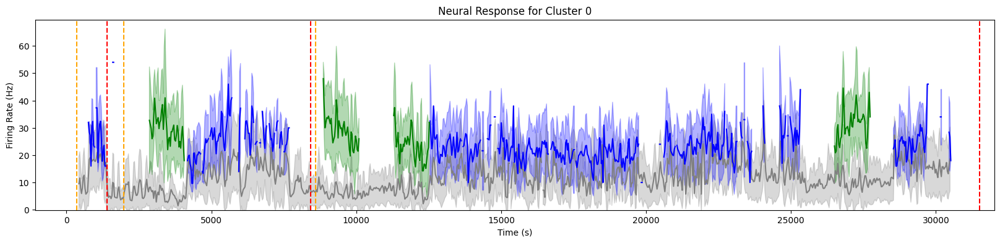

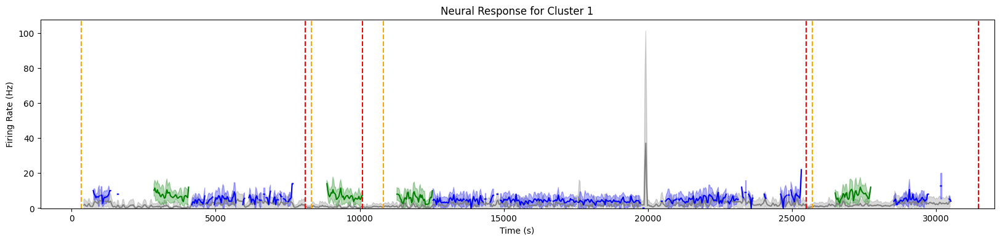

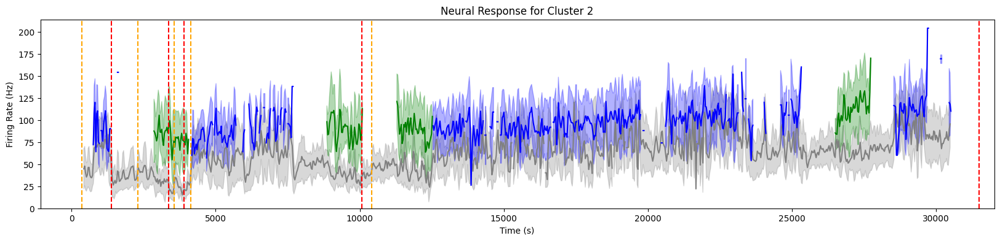

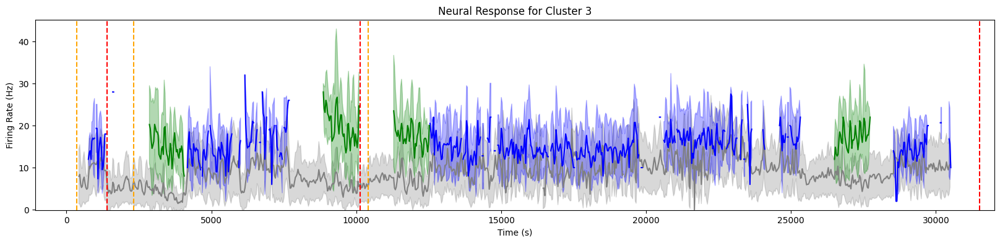

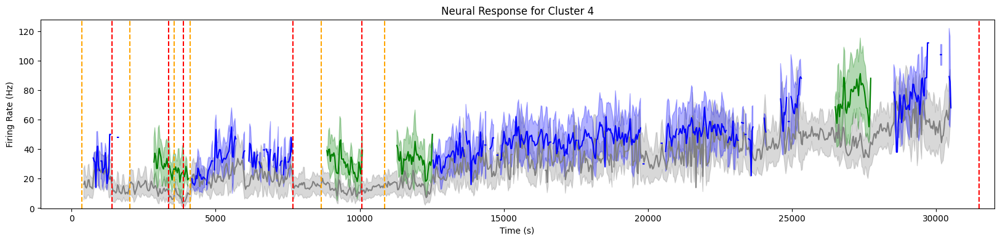

...

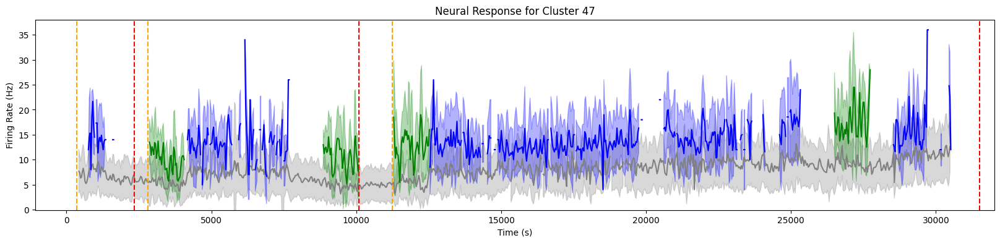

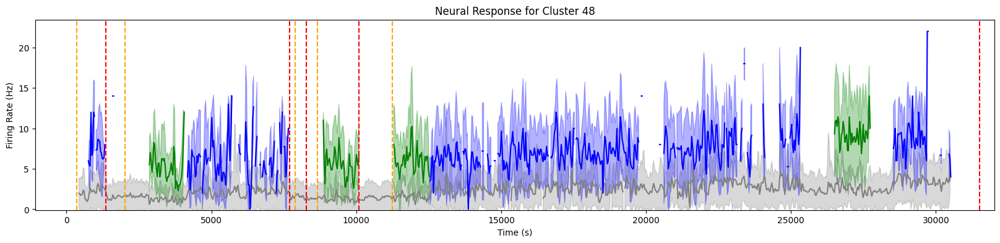

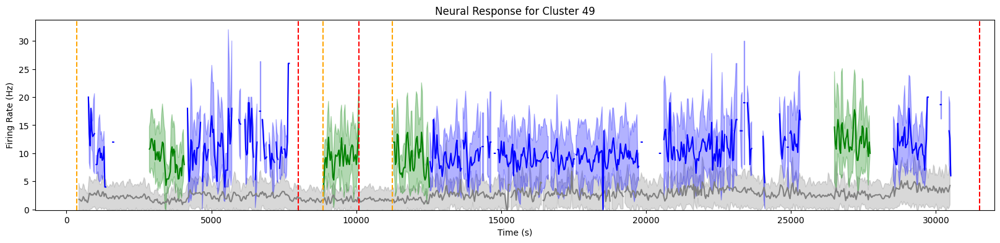

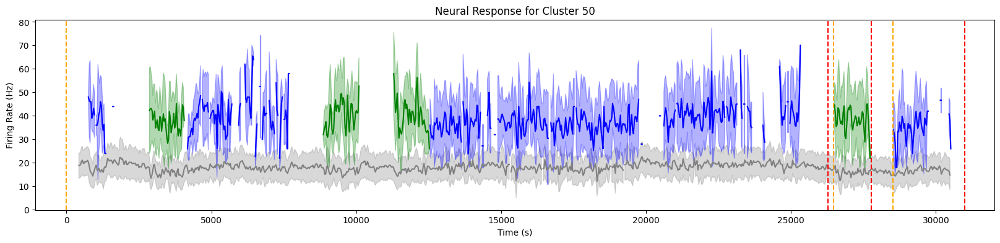

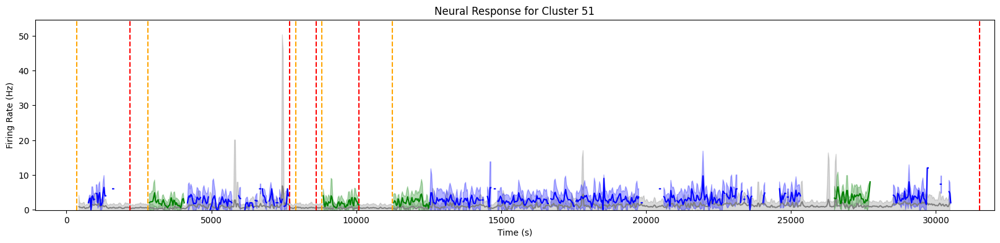

In [ ]:
plot_save_path = os.path.join('/auto/zdrive/aude/Stage_PLR1/Analysis/Neuro x Behavior/Fig. Baseline and response per unit across the day/', site.split('/')[-2] + '_cluster_')

CLUSTER_ID = []
BASELINE = []
BASELINE_TIMES = []
TRIAL_RESPONSES = []
Re_time = 2
n_ms = 0.5

for cluster in units.index :
    unit = units.loc[cluster]
    CLUSTER_ID.append(cluster)
    silence_bin_start, silence_bin_means,TRIAL_RESPONSE_UNIT = get_unit_responses_sr(unit, cluster, 
                                                                                 offset_ms = 0, n_ms = n_ms, Re_time = Re_time, 
                                                                                 plot = True, plot_save_path = plot_save_path)
    BASELINE_TIMES.append(silence_bin_start)
    BASELINE.append(silence_bin_means)
    TRIAL_RESPONSES.append(TRIAL_RESPONSE_UNIT)


In [ ]:
Z_SCORES = []

NanTrialCount = 0
ZeroBaselineCount = 0

for cid in range(len(units.index)) : 
                 
    Cluster = CLUSTER_ID[cid]
    Baseline_times_unit = np.array(BASELINE_TIMES[cid])
    Baseline_unit = np.array(BASELINE[cid])
    Trial_response_unit = TRIAL_RESPONSES[cid]
                 
    Z_score_unit = []
    for i,row in all_trials.iterrows():
        
        Trial_start_time = row.start_time
        
        if Trial_start_time > Baseline_times_unit.max():
            Local_baseline = max(Baseline_unit[-1],1/90)
#             print(Trial_start_time)
        else : 
            Local_baseline = Baseline_unit[np.where(Baseline_times_unit > Trial_start_time)[0][0]-1]
            if Local_baseline == 0 :
                New = max(np.mean([Baseline_unit[np.where(Baseline_times_unit > Trial_start_time)[0][0]-2],
                              Baseline_unit[np.where(Baseline_times_unit > Trial_start_time)[0][0]-1],
                              Baseline_unit[np.where(Baseline_times_unit > Trial_start_time)[0][0]]]), 1/90)
                Local_baseline = New
        
        Trial_response = Trial_response_unit[i]
        Z_score_unit.append([Trial_response-Local_baseline])
    mean_Zscore = np.nanmean(Z_score_unit)
    std_Zscore = np.nanstd(Z_score_unit)    
    Z_SCORES.append((np.array(Z_score_unit)-mean_Zscore)/std_Zscore)

In [ ]:
file_path = os.path.join(h5py_savepath, "unit_responses.h5")
with h5py.File(file_path, "w") as f:
    f.create_dataset("CLUSTER_ID", data=np.array(CLUSTER_ID, dtype="int32"))
    f.create_dataset("BASELINE_TIMES", data=np.array(BASELINE_TIMES, dtype=np.float64))
    f.create_dataset("BASELINE", data=np.array(BASELINE, dtype=np.float64))
    f.create_dataset("TRIAL_RESPONSES", data=np.array(TRIAL_RESPONSES, dtype=np.float64))
    f.create_dataset("Z_SCORES", data=np.array(Z_SCORES, dtype=np.float64))